#  The Odyssey at the Cinema: An Exploration of Modern-Day Film
## Exploratory Data Analysis
**Introduction to Data Visualization**

**Dataset:** This project uses the ultimate 1 Million Movies dataset exported to Kaggle from The Movie Database (TMDB). TMDB metadata is joined with IMDb ratings and vote counts and is refreshed daily the data from this project was collected on November 20th, 2026.

**Scope:** This analsysis was limited to films **released after 2015**, leading to a start date of `release_date >= 2016-01-01`.

This notebook covers the exploratory data analysis used to create the scrollytelling page **ONLY**. It **DOES NOT** contain a website or front-end code.

## Step 1: Setup

In [318]:
import os, json, warnings
from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import networkx as nx
import sklearn

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
warnings.filterwarnings("ignore", category=FutureWarning)
print("pandas", pd.__version__, "| networkx", nx.__version__)

pandas 3.1.1 | networkx 3.6.1


### Configuration

In [319]:
DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
FIG_DIR  = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("processed"); OUT_DIR.mkdir(exist_ok=True)

DATA_PATH  = DATA_DIR / "TMDB_2016plus.csv"
CACHE_PATH = DATA_DIR / "tmdb_2016plus.parquet"
USE_CACHE  = True

START_DATE = pd.Timestamp("2016-01-01")
START_YEAR = START_DATE.year
TODAY      = pd.Timestamp.today().normalize()

LIST_SEP = ", " # delimiter

# "Notable" film = enough audience attention for ratings to mean something
NOTABLE_MIN_IMDB_VOTES = 1_000
FEATURE_MIN_RUNTIME    = 40 # minutes

CAST_TOP_K      = 5 # top-billed actors per film used for people/network analysis
MIN_EDGE_WEIGHT = 2 # actors must share >= this many films to be linked
MIN_KW_FILMS    = 40 # keyword must appear in >= this many notable films to be trend-ranked

BIG_BOX_TIERS      = ["Major studio"] # studio tiers that count as "big box"
MIN_DIRECTOR_FILMS = 3 # directors need >= this many notable films for director stats

### Chart style
Shared style: thin marks, hairline grid, one hue for single-series charts, a single-hue blue ramp for magnitudes (heatmaps), and a blue/red diverging scale with a neutral gray midpoint for correlations. Categorical colors are always assigned in fixed order.

In [320]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = SERIES[0], SERIES[1]
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_LIGHT = "#9ec5f4"
SEQ  = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
DIV  = LinearSegmentedColormap.from_list("div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52f2f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "axes.titlecolor": INK, "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 2, "patch.linewidth": 0,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.family": "sans-serif", "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})

def human(x, prefix=""):
    a = abs(x)
    for v, s in [(1e9, "B"), (1e6, "M"), (1e3, "k")]:
        if a >= v:
            return f"{prefix}{x / v:.3g}{s}"
    return f"{prefix}{x:.3g}"
HUMAN = mtick.FuncFormatter(lambda x, p: human(x))
MONEY = mtick.FuncFormatter(lambda x, p: human(x, "$"))
PCT   = mtick.PercentFormatter(1.0, decimals=0)

BOX_KW = dict(fliersize=0, linewidth=0.8, width=0.6, medianprops={"color": INK, "linewidth": 1.5},
              whiskerprops={"color": AXIS}, capprops={"color": AXIS}, boxprops={"edgecolor": AXIS})

def titles(ax, title, sub=None):
    ax.set_title(title, pad=22 if sub else 8)
    if sub:
        ax.annotate(sub, xy=(0, 1), xycoords="axes fraction", xytext=(0, 5),
                    textcoords="offset points", fontsize=9, color=INK_2, va="bottom")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def hbar(ax, s, title, sub=None, fmt=HUMAN, color=BLUE):
    s = s.sort_values()
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(fmt)
    titles(ax, title, sub)

def dot_compare(frame, cols, labels, title, sub=None, fmt=PCT, ax=None):
    # Cleveland dot plot
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.3 * len(frame) + 1.4))
    y = np.arange(len(frame))
    ax.hlines(y, frame[cols].min(axis=1), frame[cols].max(axis=1), color=GRID, lw=2, zorder=1)
    for i, c in enumerate(cols):
        ax.scatter(frame[c], y, s=46, color=SERIES[i], label=labels[i], zorder=3,
                   edgecolor=SURFACE, linewidth=1.5)
    ax.set_yticks(y, frame.index)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(fmt)
    ax.legend(loc="lower right")
    titles(ax, title, sub)
    return ax

def explode_list(frame, col, top_k=None, keep=("id", "year")):
    s = frame[col].dropna().astype(str).str.split(LIST_SEP)
    if top_k:
        s = s.str[:top_k]
    out = frame.loc[s.index, list(keep)].assign(**{col: s}).explode(col)
    out[col] = out[col].str.strip()
    return out[out[col].notna() & (out[col] != "")].reset_index(drop=True)

## Step 2: Check input file

In [321]:
assert DATA_PATH.exists(), (
    f"{DATA_PATH.resolve()} not found. Put TMDB_2016plus.csv in the same folder as this notebook. "
    "On iCloud-synced folders, right-click it in Finder and choose 'Keep Downloaded'.")

size_mb = DATA_PATH.stat().st_size / 1e6
csv_time = pd.Timestamp(DATA_PATH.stat().st_mtime, unit="s")
cache_fresh = CACHE_PATH.exists() and pd.Timestamp(CACHE_PATH.stat().st_mtime, unit="s") >= csv_time
need_csv = not (USE_CACHE and cache_fresh)

print(f"CSV: {DATA_PATH}  |  {size_mb:,.0f} MB  |  file date {csv_time.date()}")
print("Using cache:", not need_csv)

CSV: data/TMDB_2016plus.csv  |  277 MB  |  file date 2026-11-20
Using cache: False


## Step 3: Load
**File read in chunks

In [322]:
def load_filtered(path, start=START_DATE, chunksize=200_000):
    kept, n_total, n_dated = [], 0, 0
    for chunk in pd.read_csv(path, chunksize=chunksize, dtype=str, on_bad_lines="warn"):
        n_total += len(chunk)
        d = pd.to_datetime(chunk["release_date"], errors="coerce", format="ISO8601")
        n_dated += int(d.notna().sum())
        kept.append(chunk.loc[d >= start])
    out = pd.concat(kept, ignore_index=True)
    stats = {"rows_in_file": n_total, "rows_with_release_date": n_dated, "rows_2016_plus_raw": len(out)}
    return out, stats

df, load_stats = load_filtered(DATA_PATH)

RAW_COLS = list(df.columns)
print(json.dumps(load_stats, indent=2))
print(f"{len(RAW_COLS)} columns:", RAW_COLS)

{
  "rows_in_file": 485176,
  "rows_with_release_date": 485176,
  "rows_2016_plus_raw": 485176
}
30 columns: ['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']


In [323]:
df.sample(3, random_state=1).T

,465234,464815,329367
id,1759173,1757947,1383624
title,Caminho Sinuoso,Jeriji Patin,A Brief Escape
vote_average,0.0,0.0,0.0
vote_count,0.0,0.0,0.0
status,Released,Released,Released
release_date,2026-07-03,2022-01-01,2021-04-28
revenue,0.0,0.0,0.0
runtime,0.0,87.0,8.0
budget,0.0,0.0,0.0
imdb_id,NaN,NaN,NaN


**Check the list delimiter.** Columns like `genres`, `cast` and `keywords` are stored as single strings. Look at a few raw values below and confirm that items are separated by `", "`. Also check whether any company or person names contain a comma, since that would break the split. If the format is different, change `LIST_SEP` in the configuration cell.

In [324]:
LIST_COLS = [c for c in ["genres", "keywords", "cast", "director", "writers", "producers",
                         "music_composer", "director_of_photography", "production_companies",
                         "production_countries", "spoken_languages"] if c in df.columns]
for c in LIST_COLS:
    ex = df[c].dropna()
    print(f"{c:<26} {ex.iloc[0][:110] if len(ex) else '(empty)'}")

genres                     Documentary
keywords                   race against time|rescue mission|family in danger|violent confrontation|relentless pursuit|high‑stakes mission
cast                       Luke Hemsworth, Morgan Freeman, Joseph Baena, Maurice P. Kerry, Mykel Shannon Jenkins, Grant Feely, Connor DeW
director                   Dimitri Logothetis
writers                    Dimitri Logothetis, Gary Scott Thompson
producers                  Ford Corbett, Ryan Winterstern, Nathan Klingher, Joel Shapiro, Dimitri Logothetis, Wayne Mogel
music_composer             Dan Romer
director_of_photography    Gerardo Madrazo
production_companies       magiCity Studios, 120dB Films, Acme Rocket Fuel
production_countries       Germany
spoken_languages           English


## Step 4: Clean and engineer features

In [325]:
clean_log = []
def log(step, n_affected):
    clean_log.append({"step": step, "rows_affected": int(n_affected), "rows_after": len(df)})

NUM_COLS = [c for c in ["vote_average", "vote_count", "revenue", "runtime", "budget",
                        "popularity", "imdb_rating", "imdb_votes"] if c in df.columns]
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["id"] = pd.to_numeric(df["id"], errors="coerce").astype("Int64")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce", format="ISO8601")
for c in df.columns.intersection(LIST_COLS + ["title", "overview", "tagline", "status",
                                              "original_language", "certification_us"]):
    df[c] = df[c].str.strip().replace("", np.nan)
log("loaded 2016+ rows", 0)

n = len(df); df = df.drop_duplicates("id"); log("drop duplicate id", n - len(df))
n = len(df); df = df[df["release_date"] <= TODAY]; log("drop future release dates", n - len(df))

print("status values (before filtering):"); print(df["status"].value_counts(dropna=False), "\n")
n = len(df); df = df[df["status"] == "Released"]; log("keep status == Released", n - len(df))

for c in ["budget", "revenue", "runtime"]:
    m = df[c] == 0; df.loc[m, c] = np.nan; log(f"{c}: 0 -> missing", m.sum())
for c in ["budget", "revenue"]:
    m = df[c].between(0, 1_000, inclusive="neither"); df.loc[m, c] = np.nan; log(f"{c}: < $1,000 -> missing", m.sum())
RUNTIME_MAX = 240  # longer entries are usually miniseries, compilations, or errors
m = df["runtime"] > RUNTIME_MAX; df.loc[m, "runtime"] = np.nan; log(f"runtime > {RUNTIME_MAX} min -> missing", m.sum())
m = df["vote_count"].fillna(0) == 0; df.loc[m, "vote_average"] = np.nan; log("vote_average w/o votes -> missing", m.sum())
m = df["imdb_votes"].fillna(0) == 0; df.loc[m, ["imdb_rating", "imdb_votes"]] = np.nan; log("imdb rating w/o votes -> missing", m.sum())

df = df.reset_index(drop=True)
pd.DataFrame(clean_log)

status values (before filtering):
status
Released           485031
Post Production        68
In Production          55
Planned                18
Canceled                4
Name: count, dtype: int64 



,step,rows_affected,rows_after
0,loaded 2016+ rows,0,485176
1,drop duplicate id,0,485176
2,drop future release dates,0,485176
3,keep status == Released,145,485031
4,budget: 0 -> missing,435955,485031
5,revenue: 0 -> missing,473726,485031
6,runtime: 0 -> missing,101454,485031
7,"budget: < $1,000 -> missing",20188,485031
8,"revenue: < $1,000 -> missing",2860,485031
9,runtime > 240 min -> missing,1131,485031


In [326]:
# Derived features
df["year"]  = df["release_date"].dt.year.astype(int)
df["month"] = df["release_date"].dt.month
df["dow"]   = df["release_date"].dt.day_name()
df["is_feature"] = df["runtime"] >= FEATURE_MIN_RUNTIME
df["genre_list"] = df["genres"].str.split(LIST_SEP)
df["n_genres"]   = df["genre_list"].str.len().fillna(0).astype(int)
df["primary_genre"] = df["genre_list"].str[0]
df["roi"] = df["revenue"] / df["budget"] # NaN unless both known
df["notable"] = (df["imdb_votes"] >= NOTABLE_MIN_IMDB_VOTES) & df["is_feature"]

STUDIO_TIERS = {
    "Major studio": [r"walt disney pictures", r"walt disney animation", r"marvel studios", r"lucasfilm", r"pixar",
        r"20th century (?:studios|fox)", r"twentieth century fox", r"warner bros\.? (?:pictures|animation)",
        r"new line cinema", r"dc (?:films|studios|entertainment)", r"universal pictures", r"illumination",
        r"dreamworks animation", r"paramount pictures", r"paramount animation", r"nickelodeon movies",
        r"columbia pictures", r"sony pictures animation", r"screen gems", r"tristar pictures"],
    "Studio specialty arm": [r"focus features", r"searchlight pictures", r"sony pictures classics", r"warner independent"],
    "Mini-major": [r"lionsgate", r"lions gate", r"summit entertainment", r"metro-goldwyn-mayer", r"\bmgm\b", r"\bstx"],
    "Streamer": [r"netflix", r"amazon (?:studios|mgm studios)", r"apple (?:studios|original films)"],
}
TIER_ORDER  = list(STUDIO_TIERS) + ["Independent/other", "Unknown (no companies listed)"]
TIER_COLORS = dict(zip(TIER_ORDER, SERIES[:5] + [AXIS]))

pc = df["production_companies"].str.lower()
df["studio_tier"] = np.where(pc.isna(), "Unknown (no companies listed)", "Independent/other")
assigned = pd.Series(False, index=df.index)
for tier, pats in STUDIO_TIERS.items():
    hit = pc.str.contains("|".join(pats), regex=True, na=False) & ~assigned
    df.loc[hit, "studio_tier"] = tier
    assigned |= hit
df["big_box"] = df["studio_tier"].isin(BIG_BOX_TIERS)

nb = df[df["notable"]].copy() # rebuild the notable subset with the new columns
pd.DataFrame({"all 2016+": df["studio_tier"].value_counts(), "notable": nb["studio_tier"].value_counts()}).reindex(TIER_ORDER)

CURRENT_YEAR   = int(df["year"].max())
PARTIAL_YEAR   = df["release_date"].max() < pd.Timestamp(f"{CURRENT_YEAR}-12-31")
LAST_FULL_YEAR = CURRENT_YEAR - 1 if PARTIAL_YEAR else CURRENT_YEAR
YEARS_FULL     = list(range(START_YEAR, LAST_FULL_YEAR + 1))

nb = df[df["notable"]].copy() # the 'notable' working subset used for most of the analysis
print(f"2016+ released films: {len(df):,}   |   notable: {len(nb):,} ({len(nb)/len(df):.1%})")
print(f"Latest release date: {df['release_date'].max().date()}  ->  {CURRENT_YEAR} partial: {PARTIAL_YEAR}")

# Studio tier from production_companies (first matching tier wins)
STUDIO_TIERS = {
    "Major studio": [r"walt disney pictures", r"walt disney animation", r"marvel studios", r"lucasfilm", r"pixar",
        r"20th century (?:studios|fox)", r"twentieth century fox", r"warner bros\.? (?:pictures|animation)",
        r"new line cinema", r"dc (?:films|studios|entertainment)", r"universal pictures", r"illumination",
        r"dreamworks animation", r"paramount pictures", r"paramount animation", r"nickelodeon movies",
        r"columbia pictures", r"sony pictures animation", r"screen gems", r"tristar pictures"],
    "Studio specialty arm": [r"focus features", r"searchlight pictures", r"sony pictures classics", r"warner independent"],
    "Mini-major": [r"lionsgate", r"lions gate", r"summit entertainment", r"metro-goldwyn-mayer", r"\bmgm\b", r"\bstx"],
    "Streamer": [r"netflix", r"amazon (?:studios|mgm studios)", r"apple (?:studios|original films)"],
}
TIER_ORDER = list(STUDIO_TIERS) + ["Independent/other", "Unknown (no companies listed)"]

pc = df["production_companies"].str.lower()
df["studio_tier"] = np.where(pc.isna(), "Unknown (no companies listed)", "Independent/other")
assigned = pd.Series(False, index=df.index)
for tier, pats in STUDIO_TIERS.items():
    hit = pc.str.contains("|".join(pats), regex=True, na=False) & ~assigned
    df.loc[hit, "studio_tier"] = tier
    assigned |= hit

nb = df[df["notable"]].copy() # rebuild the notable subset so it carries the new column
nb["studio_tier"].value_counts().reindex(TIER_ORDER)

2016+ released films: 485,031   |   notable: 18,055 (3.7%)
Latest release date: 2026-11-20  ->  2026 partial: True


studio_tier
Major studio                       885
Studio specialty arm                89
Mini-major                         340
Streamer                           106
Independent/other                15430
Unknown (no companies listed)     1205
Name: count, dtype: int64

## Step 5: Missingness

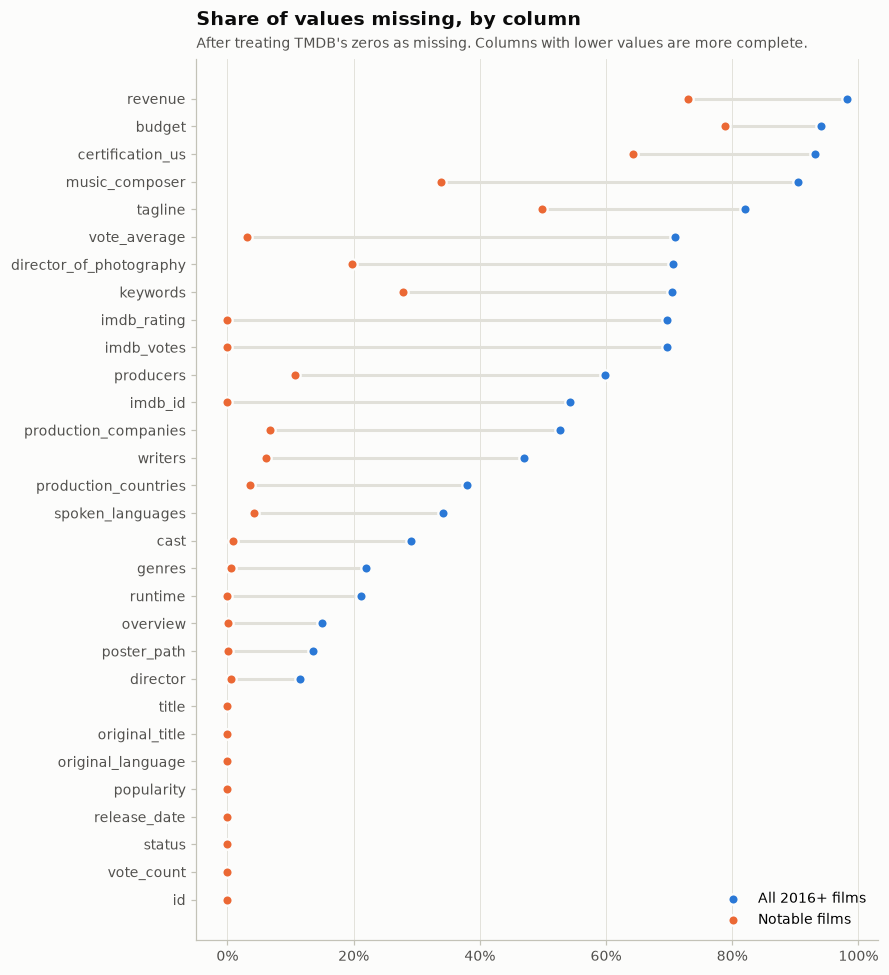

,all,notable
id,0.0%,0.0%
vote_count,0.0%,0.0%
status,0.0%,0.0%
release_date,0.0%,0.0%
popularity,0.0%,0.0%
original_language,0.0%,0.0%
original_title,0.0%,0.0%
title,0.0%,0.0%
director,11.5%,0.6%
poster_path,13.5%,0.2%


In [327]:
miss = pd.DataFrame({
    "all": df[RAW_COLS].isna().mean(),
    "notable": nb[RAW_COLS].isna().mean(),
}).sort_values("all")
dot_compare(miss, ["all", "notable"], ["All 2016+ films", "Notable films"],
            "Share of values missing, by column",
            "After treating TMDB's zeros as missing. Columns with lower values are more complete.")
save(plt.gcf(), "05_missingness"); plt.show()
miss.style.format("{:.1%}")

*Things to note:* how complete `budget`/`revenue` are (finance questions only work on a small subset); `keywords` coverage (this is the motif layer); and how much better coverage is for notable films (a **selection bias** to state in Limitations).

## Step 6: How many of these films did anyone watch?

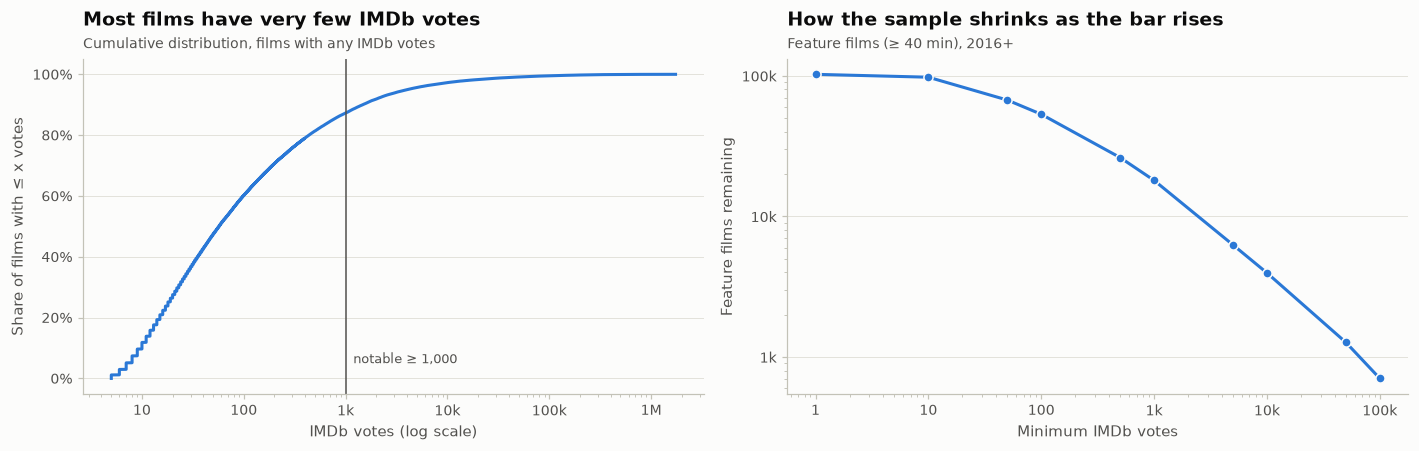

Films with no IMDb match/votes: 69.7%
Films with < 10 TMDB votes:     93.5%
Share of all IMDb votes held by the top 1% of films: 84.9%
1         102567
10         97843
50         67326
100        53331
500        26248
1000       18055
5000        6280
10000       3969
50000       1273
100000       705


In [328]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

v = df["imdb_votes"].dropna().sort_values()
axes[0].plot(v.values, np.arange(1, len(v) + 1) / len(v), color=BLUE)
axes[0].set_xscale("log"); axes[0].xaxis.set_major_formatter(HUMAN); axes[0].yaxis.set_major_formatter(PCT)
axes[0].axvline(NOTABLE_MIN_IMDB_VOTES, color=INK_2, lw=1)
axes[0].annotate(f"notable ≥ {NOTABLE_MIN_IMDB_VOTES:,}", (NOTABLE_MIN_IMDB_VOTES, 0.05),
                 xytext=(5, 0), textcoords="offset points", fontsize=8.5, color=INK_2)
axes[0].set_xlabel("IMDb votes (log scale)"); axes[0].set_ylabel("Share of films with ≤ x votes")
titles(axes[0], "Most films have very few IMDb votes", "Cumulative distribution, films with any IMDb votes")

thr = [1, 10, 50, 100, 500, 1_000, 5_000, 10_000, 50_000, 100_000]
remain = [int(((df["imdb_votes"] >= t) & df["is_feature"]).sum()) for t in thr]
axes[1].plot(thr, remain, marker="o", color=BLUE, markersize=6, markeredgecolor=SURFACE)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].xaxis.set_major_formatter(HUMAN); axes[1].yaxis.set_major_formatter(HUMAN)
axes[1].set_xlabel("Minimum IMDb votes"); axes[1].set_ylabel("Feature films remaining")
titles(axes[1], "How the sample shrinks as the bar rises", "Feature films (≥ 40 min), 2016+")
plt.tight_layout(); save(fig, "06_long_tail"); plt.show()

tot = df["imdb_votes"].sum()
top1 = df["imdb_votes"].nlargest(max(1, int(len(df) * 0.01))).sum()
print(f"Films with no IMDb match/votes: {df['imdb_votes'].isna().mean():.1%}")
print(f"Films with < 10 TMDB votes:     {(df['vote_count'].fillna(0) < 10).mean():.1%}")
print(f"Share of all IMDb votes held by the top 1% of films: {top1 / tot:.1%}")
print(pd.Series(remain, index=thr, name="feature films remaining").to_string())

**Recency bias in the threshold.** A 2024 film has had less time to collect votes than a 2016 film, so a fixed vote threshold under-counts recent years. The comparison below sets the fixed rule next to a *within-year* alternative (the top N% of each year's feature films by votes). If the two diverge, say so in Limitations, or switch the definition.

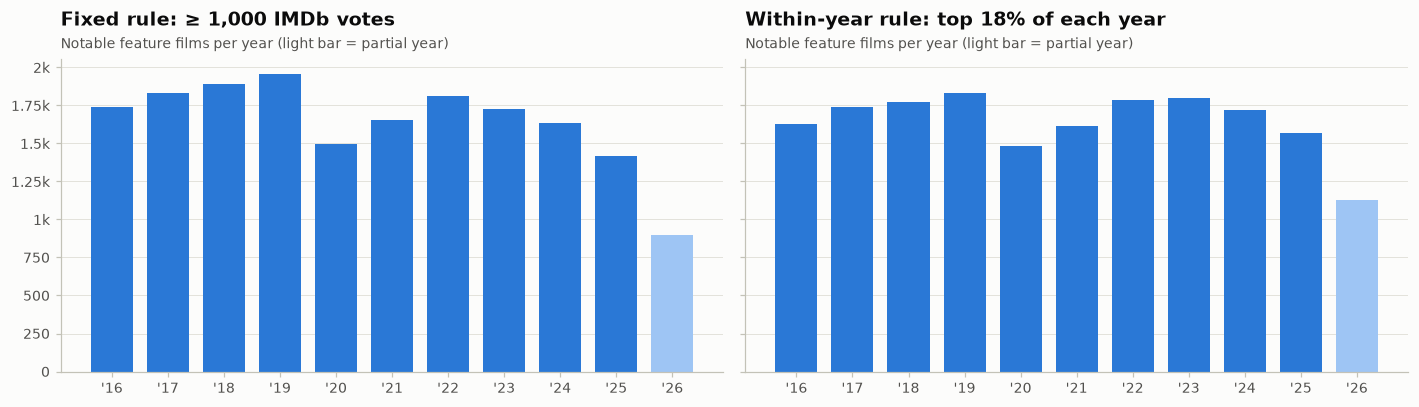

In [329]:
feat = df[df["is_feature"] & df["imdb_votes"].notna()].copy()
feat["votes_pct_in_year"] = feat.groupby("year")["imdb_votes"].rank(pct=True)
share_notable = nb.shape[0] / max(1, feat.shape[0])
alt = feat[feat["votes_pct_in_year"] >= 1 - share_notable]

cmp = pd.DataFrame({"fixed": nb.groupby("year").size(), "within_year": alt.groupby("year").size()}).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, lab in zip(axes, ["fixed", "within_year"],
                        [f"Fixed rule: ≥ {NOTABLE_MIN_IMDB_VOTES:,} IMDb votes",
                         f"Within-year rule: top {share_notable:.0%} of each year"]):
    colors = [BLUE if y <= LAST_FULL_YEAR else BLUE_LIGHT for y in cmp.index]
    ax.bar(cmp.index, cmp[col], color=colors, width=0.75)
    ax.set_xticks(cmp.index, [f"'{str(y)[2:]}" for y in cmp.index]); ax.yaxis.set_major_formatter(HUMAN)
    titles(ax, lab, "Notable feature films per year (light bar = partial year)")
plt.tight_layout(); save(fig, "06_notable_definitions"); plt.show()

## Step 7: Release volume

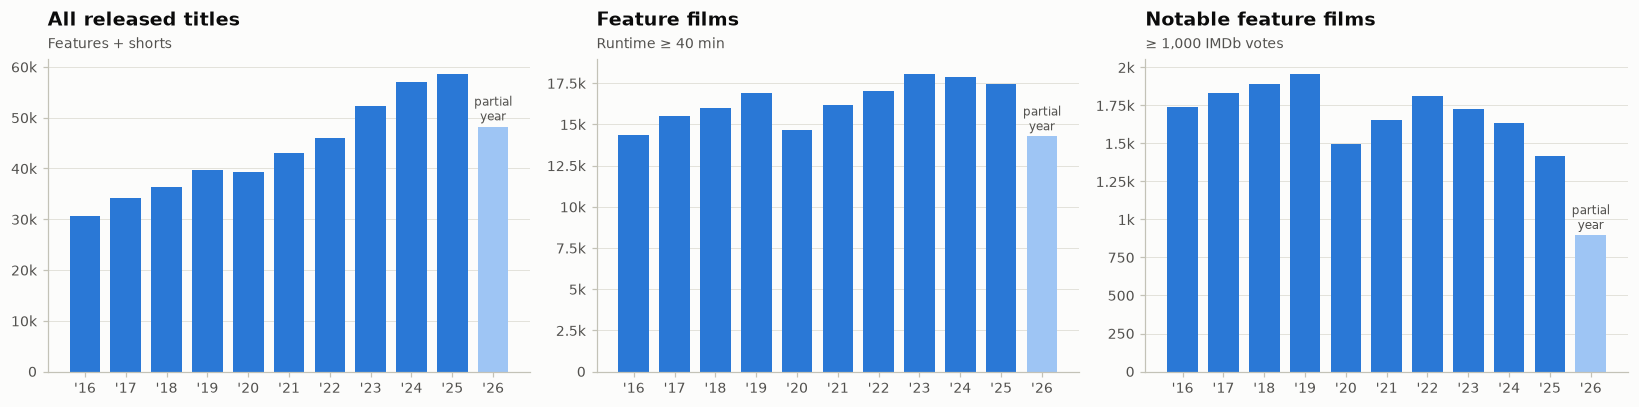

In [330]:
def year_bars(ax, counts, title, sub=None):
    colors = [BLUE if y <= LAST_FULL_YEAR else BLUE_LIGHT for y in counts.index]
    ax.bar(counts.index, counts.values, color=colors, width=0.75)
    ax.set_xticks(counts.index, [f"'{str(y)[2:]}" for y in counts.index])
    ax.yaxis.set_major_formatter(HUMAN)
    if counts.index.max() > LAST_FULL_YEAR:
        ax.annotate("partial\nyear", (counts.index.max(), counts.iloc[-1]), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_2)
    titles(ax, title, sub)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
year_bars(axes[0], df.groupby("year").size(), "All released titles", "Features + shorts")
year_bars(axes[1], df[df["is_feature"]].groupby("year").size(), "Feature films", f"Runtime ≥ {FEATURE_MIN_RUNTIME} min")
year_bars(axes[2], nb.groupby("year").size(), "Notable feature films", f"≥ {NOTABLE_MIN_IMDB_VOTES:,} IMDb votes")
plt.tight_layout(); save(fig, "07_volume_by_year"); plt.show()

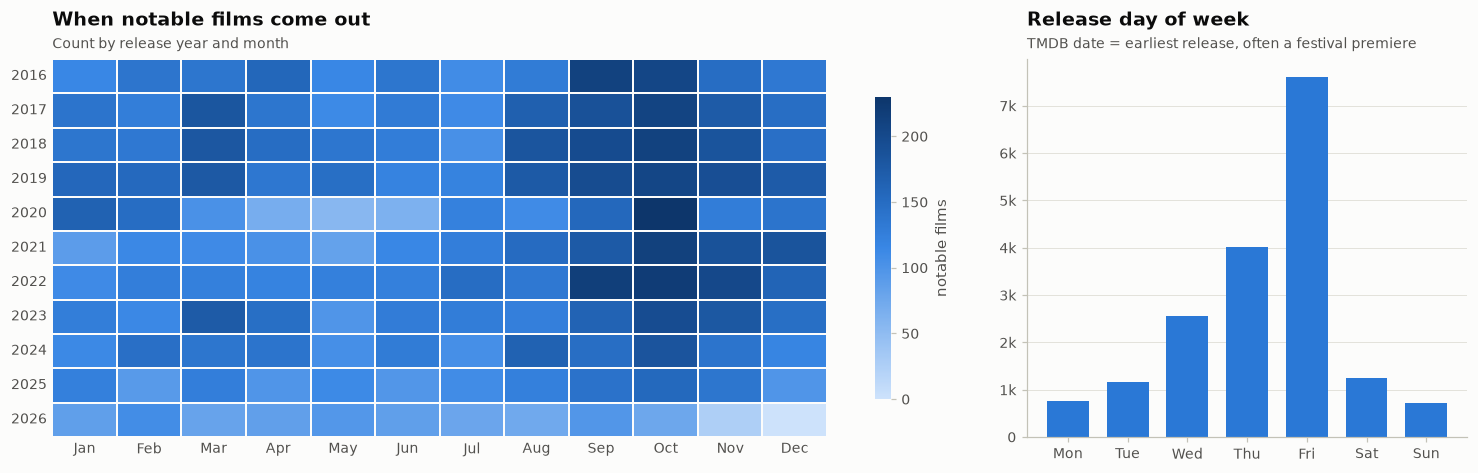

In [331]:
ym = nb.groupby(["year", "month"]).size().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
ym.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(ym, cmap=SEQ, linewidths=1, linecolor=SURFACE, ax=axes[0],
            cbar_kws={"label": "notable films", "shrink": 0.8})
axes[0].set_xlabel(""); axes[0].set_ylabel(""); axes[0].tick_params(colors=INK_2, length=0)
titles(axes[0], "When notable films come out", "Count by release year and month")

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = nb["dow"].value_counts().reindex(order).fillna(0)
axes[1].bar([d[:3] for d in order], dow.values, color=BLUE, width=0.7)
axes[1].yaxis.set_major_formatter(HUMAN)
titles(axes[1], "Release day of week", "TMDB date = earliest release, often a festival premiere")
plt.tight_layout(); save(fig, "07_month_dow"); plt.show()

## Step 8: Distributions of numeric fields

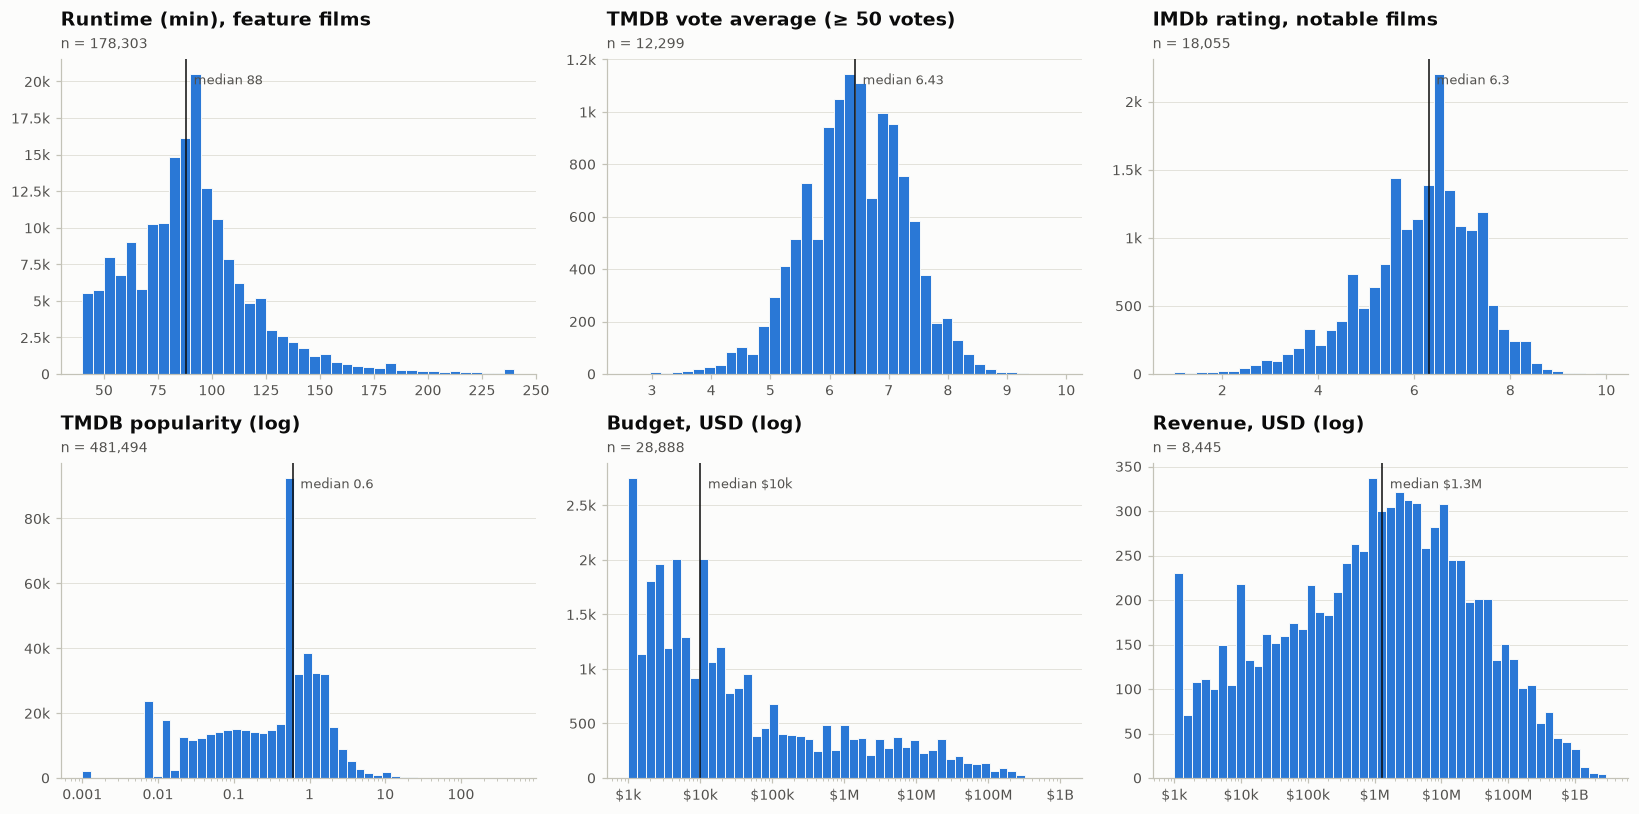

,count,mean,std,min,5%,25%,50%,75%,95%,max
runtime,"18,055.000",106.262,22.688,40.000,78.700,90.000,102.000,119.000,149.000,238.000
vote_average,"17,489.000",6.244,1.086,0.000,4.300,5.700,6.343,6.966,7.800,10.000
vote_count,"18,055.000",439.958,"1,544.489",0.000,2.000,23.000,65.000,226.000,"1,888.300","33,646.000"
imdb_rating,"18,055.000",6.090,1.198,1.000,3.800,5.400,6.300,6.900,7.800,10.000
imdb_votes,"18,055.000","18,068.484","65,705.525","1,000.000","1,096.000","1,598.000","2,911.000","8,329.500","75,596.900","1,737,623.000"
popularity,"18,055.000",3.113,9.553,0.000,0.421,1.098,1.800,3.075,8.141,507.504
budget,"3,809.000","27,023,579.439","48,456,593.163","1,600.000","200,000.000","2,800,000.000","9,898,623.000","26,000,000.000","125,000,000.000","658,800,000.000"
revenue,"4,888.000","56,785,318.809","175,172,620.469","1,008.000","28,843.500","677,209.500","4,695,825.500","29,308,263.000","297,597,453.500","2,942,649,778.000"
roi,"2,753.000",4.800,25.893,0.000,0.022,0.426,1.410,3.595,12.531,699.210


In [332]:
specs = [
    ("runtime",      df[df["is_feature"]]["runtime"].clip(upper=240), "Runtime (min), feature films", False),
    ("vote_average", df.loc[df["vote_count"] >= 50, "vote_average"], "TMDB vote average (≥ 50 votes)", False),
    ("imdb_rating",  nb["imdb_rating"], "IMDb rating, notable films", False),
    ("popularity",   df["popularity"][df["popularity"] > 0], "TMDB popularity (log)", True),
    ("budget",       df["budget"], "Budget, USD (log)", True),
    ("revenue",      df["revenue"], "Revenue, USD (log)", True),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (name, s, lab, logx) in zip(axes.flat, specs):
    s = s.dropna()
    if len(s) == 0:
        ax.set_visible(False); continue
    bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 50) if logx else 40
    ax.hist(s, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
    if logx:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(MONEY if name in ("budget", "revenue") else HUMAN)
    med = s.median()
    ax.axvline(med, color=INK, lw=1)
    ax.annotate(f"median {human(med, '$' if name in ('budget','revenue') else '')}", (med, ax.get_ylim()[1] * 0.92),
                xytext=(5, 0), textcoords="offset points", fontsize=8.5, color=INK_2)
    ax.yaxis.set_major_formatter(HUMAN)
    titles(ax, lab, f"n = {len(s):,}")
plt.tight_layout(); save(fig, "08_distributions"); plt.show()

nb[["runtime", "vote_average", "vote_count", "imdb_rating", "imdb_votes", "popularity", "budget", "revenue", "roi"]].describe(
    percentiles=[.05, .25, .5, .75, .95]).T

Outlier check

In [333]:
cols = ["title", "year", "budget", "revenue", "roi", "runtime", "imdb_votes"]
display(nb.nlargest(8, "roi")[cols])
display(nb.nlargest(5, "runtime")[cols])

,title,year,budget,revenue,roi,runtime,imdb_votes
314730,Obsession,2026,"750,000.000","524,407,429.000",699.210,109.000,"433,931.000"
34804,Animal World,2018,"125,000.000","69,885,700.000",559.086,125.000,"5,540.000"
33120,One Cut of the Dead,2017,"52,406.000","27,590,180.000",526.470,96.000,"36,868.000"
14317,Secret Superstar,2017,"286,284.000","137,416,709.000",480.001,150.000,"32,935.000"
250433,Agak Laen,2024,"60,000.000","19,601,819.000",326.697,119.000,"4,026.000"
40783,Unbound,2018,"80,000.000","21,000,000.000",262.500,97.000,"1,138.000"
296477,Life After Fighting,2024,"234,325.000","59,530,099.000",254.049,126.000,"3,075.000"
266978,Demon Slayer: Kimetsu no Yaiba -To the Hashira...,2024,"200,000.000","44,354,825.000",221.774,103.000,"11,466.000"


,title,year,budget,revenue,roi,runtime,imdb_votes
222270,Musk,2026,"10,000,000.000","759,658.000",0.076,238.000,"2,605.000"
29200,An Elephant Sitting Still,2018,"2,500,000.000",NaN,NaN,235.000,"9,584.000"
404826,Dhurandhar: The Revenge,2026,"14,330,000.000","152,900,759.000",10.670,235.000,"75,463.000"
7025,The Woman Who Left,2016,NaN,NaN,NaN,229.000,"1,836.000"
143244,Pushpa 2 - The Rule,2024,"52,900,000.000","219,000,000.000",4.140,225.000,"69,302.000"


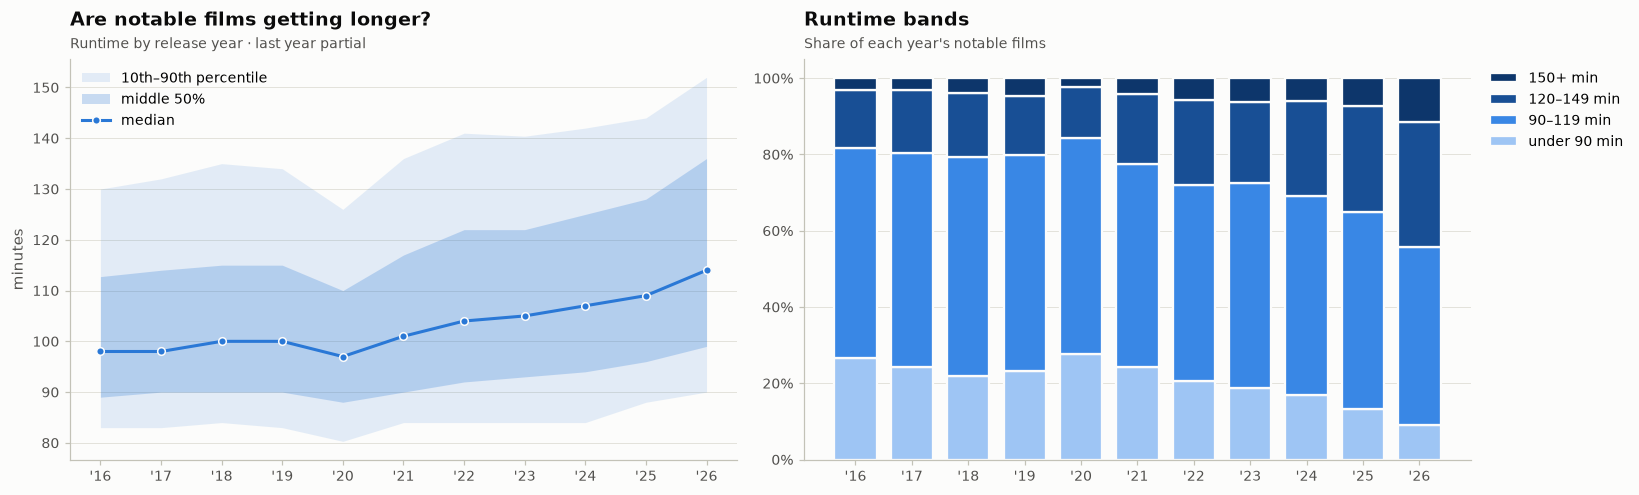

Median runtime 2016: 98 min  ->  2025: 109 min
Share 150+ min 2016: 3.2%  ->  2025: 7.2%


In [334]:
rt_nb = nb[nb["runtime"].notna()]
ry = rt_nb.groupby("year")["runtime"].quantile([.1, .25, .5, .75, .9]).unstack()
yt = [f"'{str(y)[2:]}" for y in ry.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
ax.fill_between(ry.index, ry[0.1], ry[0.9], color=BLUE, alpha=0.12, linewidth=0, label="10th–90th percentile")
ax.fill_between(ry.index, ry[0.25], ry[0.75], color=BLUE, alpha=0.25, linewidth=0, label="middle 50%")
ax.plot(ry.index, ry[0.5], color=BLUE, marker="o", markersize=5, markeredgecolor=SURFACE, label="median")
ax.set_xticks(ry.index, yt); ax.set_ylabel("minutes"); ax.legend(loc="upper left")
titles(ax, "Are notable films getting longer?", "Runtime by release year" + (" · last year partial" if PARTIAL_YEAR else ""))

bands = pd.cut(rt_nb["runtime"], bins=[0, 90, 120, 150, 1000], right=False,
               labels=["under 90 min", "90–119 min", "120–149 min", "150+ min"])
bs = pd.crosstab(rt_nb["year"], bands, normalize="index")
ax = axes[1]
bottom = np.zeros(len(bs))
for c, col in zip(bs.columns, [BLUE_RAMP[i] for i in (1, 3, 5, 6)]): # ordered bands
    ax.bar(bs.index, bs[c], bottom=bottom, color=col, width=0.75, label=c, edgecolor=SURFACE, linewidth=1.5)
    bottom += bs[c].values
ax.yaxis.set_major_formatter(PCT); ax.set_xticks(bs.index, [f"'{str(y)[2:]}" for y in bs.index])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
titles(ax, "Runtime bands", "Share of each year's notable films")
plt.tight_layout(); save(fig, "09_runtime_by_year"); plt.show()

first, last = YEARS_FULL[0], YEARS_FULL[-1]
print(f"Median runtime {first}: {ry.loc[first, 0.5]:.0f} min  ->  {last}: {ry.loc[last, 0.5]:.0f} min")
print(f"Share 150+ min {first}: {bs.loc[first, '150+ min']:.1%}  ->  {last}: {bs.loc[last, '150+ min']:.1%}")

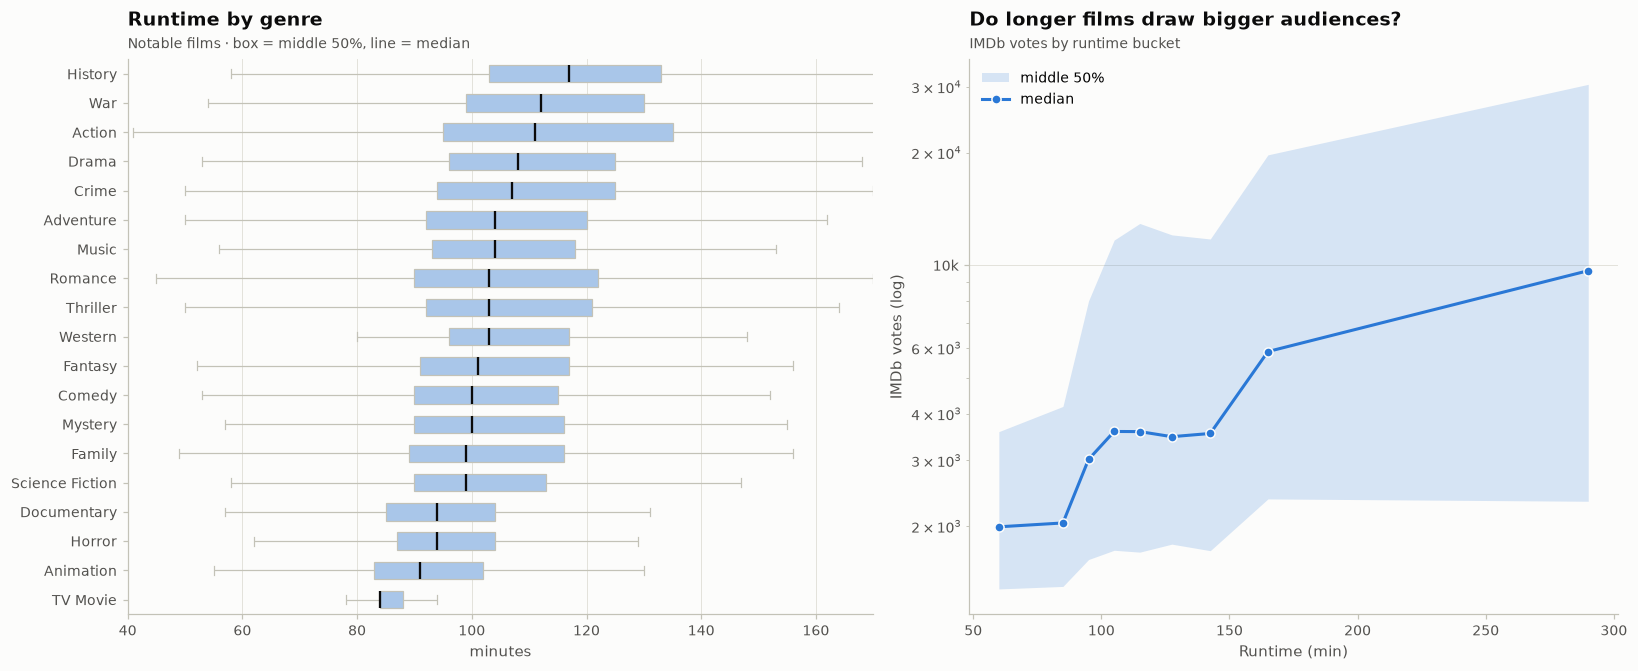

In [335]:
rg = explode_list(nb, "genres", keep=("id", "runtime")).dropna(subset=["runtime"])
order = rg.groupby("genres")["runtime"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})
sns.boxplot(data=rg, y="genres", x="runtime", order=order, ax=axes[0], color=BLUE_LIGHT, **BOX_KW)
axes[0].set_xlim(FEATURE_MIN_RUNTIME, rg["runtime"].quantile(0.99))
axes[0].set_xlabel("minutes"); axes[0].set_ylabel(""); axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False)
titles(axes[0], "Runtime by genre", "Notable films · box = middle 50%, line = median")

rb = nb[["runtime", "imdb_votes"]].dropna()
rb["bucket"] = pd.cut(rb["runtime"], bins=[40, 80, 90, 100, 110, 120, 135, 150, 180, 400])
g = rb.groupby("bucket", observed=True)["imdb_votes"]
mid = [b.mid for b in g.median().index]
axes[1].fill_between(mid, g.quantile(.25), g.quantile(.75), color=BLUE, alpha=0.18, linewidth=0, label="middle 50%")
axes[1].plot(mid, g.median(), color=BLUE, marker="o", markersize=6, markeredgecolor=SURFACE, label="median")
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(HUMAN)
axes[1].set_xlabel("Runtime (min)"); axes[1].set_ylabel("IMDb votes (log)"); axes[1].legend(loc="upper left")
titles(axes[1], "Do longer films draw bigger audiences?", "IMDb votes by runtime bucket")
plt.tight_layout(); save(fig, "09_runtime_genre_votes"); plt.show()

In [336]:
POPULAR_MIN_VOTES = 25_000 # "popular" = IMDb's Top 250 eligibility bar

is_action = nb["genres"].fillna("").str.split(LIST_SEP).apply(lambda gs: "Action" in [g.strip() for g in gs])
main_action = nb["primary_genre"].eq("Action")
rt, popular = nb["runtime"], nb["imdb_votes"] >= POPULAR_MIN_VOTES

groups = {"All notable films (baseline)": rt.notna(),
          "Over 1.5 hours (>= 90 min)": rt > 90,
          "Over 2 hours (>= 120 min)": rt > 120}
action_share = pd.DataFrame([{
    "group": label,
    "films": int(m.sum()),
    "% tagged Action": is_action[m].mean(),
    "% Action as main genre": main_action[m].mean(),
    f"popular films (≥ {POPULAR_MIN_VOTES:,} votes)": int((m & popular).sum()),
    "% of popular tagged Action": is_action[m & popular].mean(),
} for label, m in groups.items()]).set_index("group")

action_share.style.format({"films": "{:,}", f"popular films (≥ {POPULAR_MIN_VOTES:,} votes)": "{:,}",
                           "% tagged Action": "{:.1%}", "% Action as main genre": "{:.1%}",
                           "% of popular tagged Action": "{:.1%}"}, na_rep="–")

,films,% tagged Action,% Action as main genre,"popular films (≥ 25,000 votes)",% of popular tagged Action
group,,,,,
All notable films (baseline),"18,055",16.9%,10.5%,"2,151",27.8%
Over 1.5 hours (>= 90 min),"13,491",19.1%,12.2%,"1,994",28.3%
Over 2 hours (>= 120 min),"4,164",28.8%,19.1%,740,35.9%


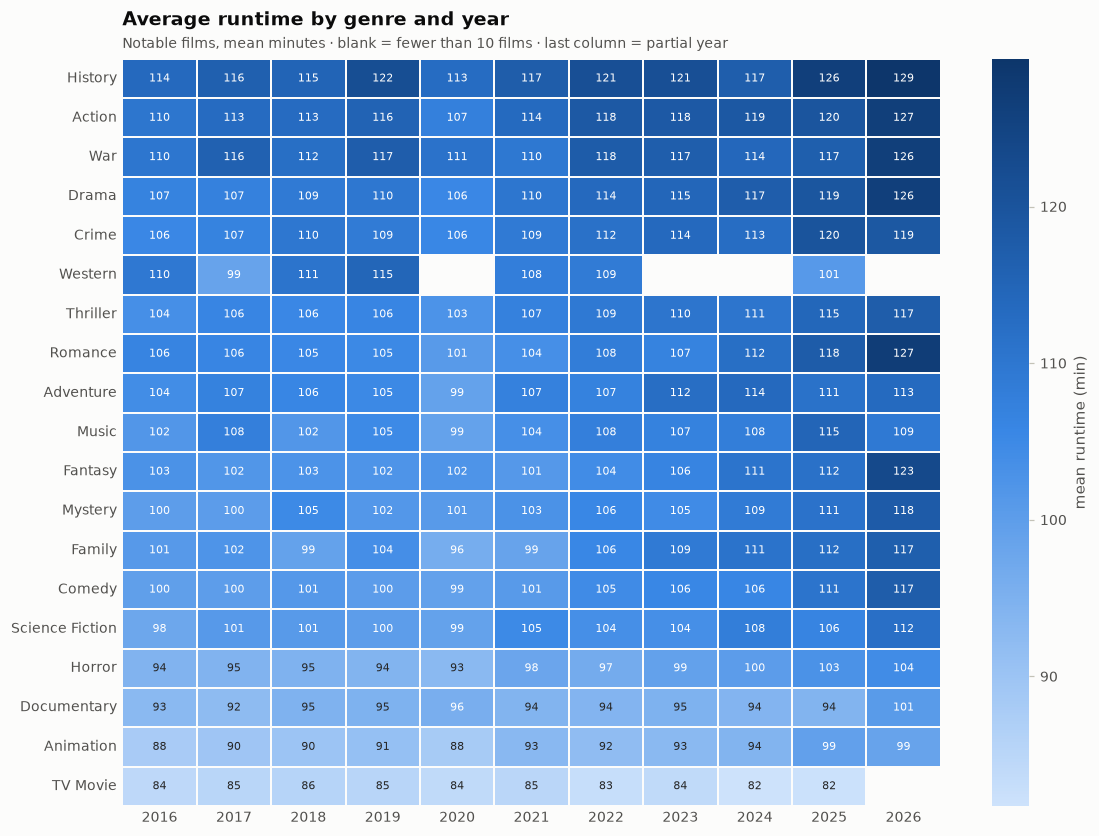

,first_3y,last_3y,films,change_min
genres,,,,
Family,101,111,"1,073",+10.1
Drama,108,117,"7,860",+9.3
Crime,107,115,"2,034",+8.0
Comedy,100,107,"5,192",+7.1
Fantasy,102,110,"1,075",+7.1
Thriller,105,112,"4,201",+6.8
Adventure,106,112,"1,237",+6.8
Action,112,119,"2,861",+6.7
History,115,122,879,+6.5


In [337]:
# Average runtime by genre and year (notable films)
MIN_FILMS_PER_CELL = 10

rgy = explode_list(nb, "genres", keep=("id", "year", "runtime")).dropna(subset=["runtime"])
cell = rgy.groupby(["genres", "year"])["runtime"].agg(["mean", "size"])
rt_gy = cell["mean"].unstack() # genres x years + mean runtime (min)
n_gy = cell["size"].unstack().reindex_like(rt_gy).fillna(0) # films behind each cell

order = rgy.groupby("genres")["runtime"].mean().sort_values(ascending=False).index
rt_gy, n_gy = rt_gy.loc[order], n_gy.loc[order]
keep = (n_gy >= MIN_FILMS_PER_CELL).any(axis=1)
rt_gy, n_gy = rt_gy[keep], n_gy[keep]

fig, ax = plt.subplots(figsize=(12, 0.38 * len(rt_gy) + 1.6))
sns.heatmap(rt_gy, mask=n_gy < MIN_FILMS_PER_CELL, cmap=SEQ, annot=True, fmt=".0f", annot_kws={"size": 7.5},
            linewidths=1, linecolor=SURFACE, ax=ax, cbar_kws={"label": "mean runtime (min)"})
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(length=0); ax.grid(False)
titles(ax, "Average runtime by genre and year",
       f"Notable films, mean minutes · blank = fewer than {MIN_FILMS_PER_CELL} films"
       + (" · last column = partial year" if PARTIAL_YEAR else ""))
save(fig, "09_runtime_genre_year"); plt.show()

yrs = [y for y in rt_gy.columns if y <= LAST_FULL_YEAR]
chg = pd.DataFrame({"first_3y": rt_gy[yrs[:3]].mean(axis=1), "last_3y": rt_gy[yrs[-3:]].mean(axis=1),
                    "films": n_gy[yrs].sum(axis=1).astype(int)})
chg["change_min"] = chg["last_3y"] - chg["first_3y"]
chg.sort_values("change_min", ascending=False).style.format(
    {"first_3y": "{:.0f}", "last_3y": "{:.0f}", "change_min": "{:+.1f}", "films": "{:,}"}, na_rep="–")

In [338]:
cols = ["title", "year", "runtime", "primary_genre", "studio_tier", "imdb_rating", "imdb_votes"]
print("Longest notable films"); display(nb.nlargest(10, "runtime")[cols])
print("Shortest notable feature films"); display(nb.nsmallest(10, "runtime")[cols])

Longest notable films


,title,year,runtime,primary_genre,studio_tier,imdb_rating,imdb_votes
222270,Musk,2026,238.000,Documentary,Independent/other,7.100,"2,605.000"
29200,An Elephant Sitting Still,2018,235.000,Drama,Independent/other,7.800,"9,584.000"
404826,Dhurandhar: The Revenge,2026,235.000,Action,Independent/other,8.200,"75,463.000"
7025,The Woman Who Left,2016,229.000,Drama,Independent/other,7.100,"1,836.000"
143244,Pushpa 2 - The Rule,2024,225.000,Drama,Independent/other,6.000,"69,302.000"
377094,Bāhubali: The Epic,2025,224.000,Action,Independent/other,8.200,"2,671.000"
478862,Haunted Hotel,2025,220.000,Comedy,Unknown (no companies listed),7.800,"12,038.000"
122829,Mr. Bachmann and His Class,2021,217.000,Documentary,Independent/other,8.000,"1,085.000"
43832,The Brutalist,2024,215.000,Drama,Independent/other,7.200,"166,747.000"
297233,Dhurandhar,2025,214.000,Action,Independent/other,8.200,"153,758.000"


Shortest notable feature films


,title,year,runtime,primary_genre,studio_tier,imdb_rating,imdb_votes
8553,The White Helmets,2016,40.000,Documentary,Independent/other,7.500,"8,596.000"
18165,Tour de Pharmacy,2017,40.000,Comedy,Independent/other,7.100,"14,211.000"
21031,Under an Arctic Sky,2017,40.000,Adventure,Unknown (no companies listed),7.000,"1,539.000"
23109,Long Shot,2017,40.000,Crime,Independent/other,7.400,"9,549.000"
32103,End Game,2018,40.000,Documentary,Independent/other,7.200,"2,276.000"
62577,Learning to Skateboard in a Warzone (If You're...,2020,40.000,Documentary,Independent/other,7.500,"1,151.000"
66567,Sturgill Simpson Presents Sound & Fury,2019,40.000,Animation,Independent/other,6.500,"2,221.000"
96130,The Speed Cubers,2020,40.000,Documentary,Independent/other,7.400,"4,487.000"
123737,Summer Ghost,2021,40.000,Animation,Independent/other,7.400,"4,068.000"
124306,The Last Cruise,2021,40.000,Documentary,Independent/other,6.400,"1,697.000"


## Step 9: Categories: genre, language, country, rating

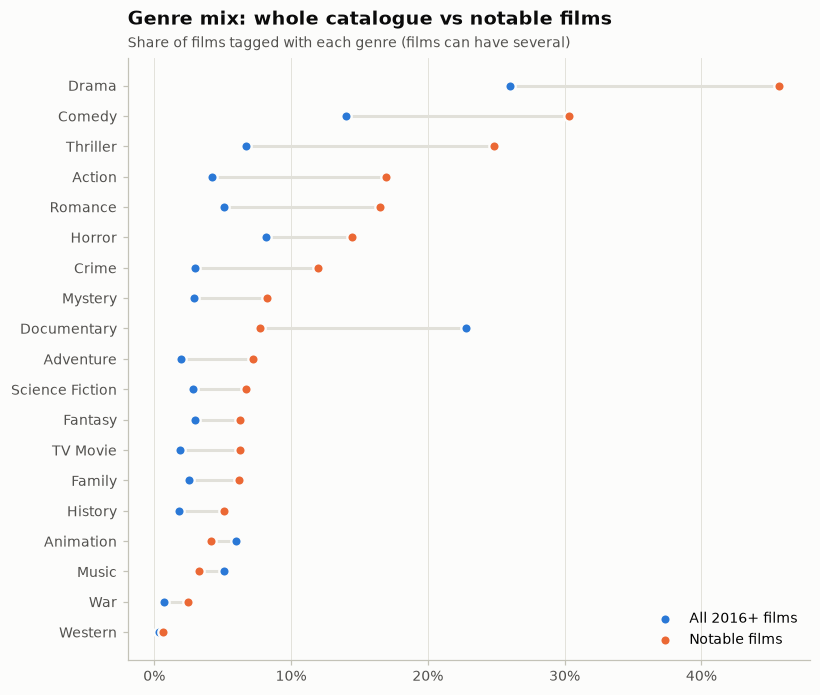

In [339]:
def share_with(frame, col):
    e = explode_list(frame, col, keep=("id",))
    return e.groupby(col)["id"].nunique() / len(frame)

gshare = pd.DataFrame({"all": share_with(df, "genres"), "notable": share_with(nb, "genres")}).fillna(0)
gshare = gshare.sort_values("notable")
dot_compare(gshare, ["all", "notable"], ["All 2016+ films", "Notable films"],
            "Genre mix: whole catalogue vs notable films",
            "Share of films tagged with each genre (films can have several)")
save(plt.gcf(), "09_genre_share"); plt.show()

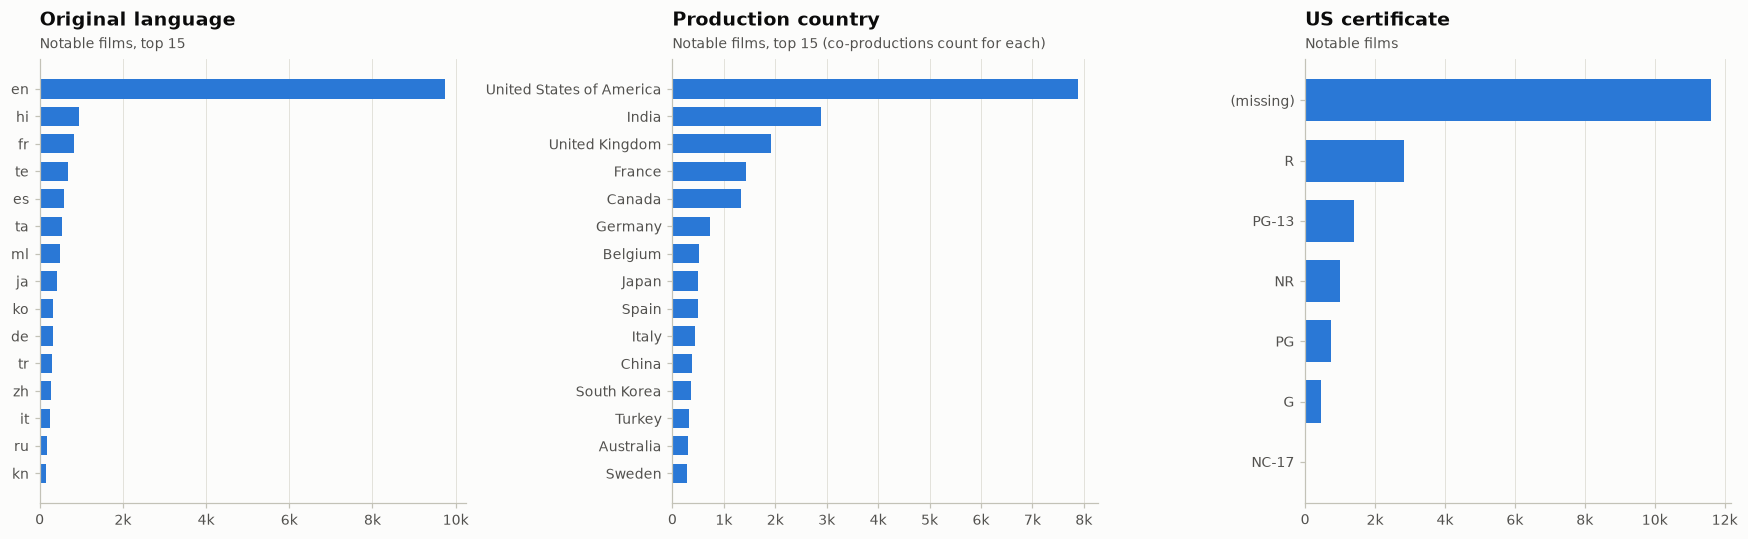

English-language share: all 46.8% | notable 54.0%
Genres per film (notable):
n_genres
0     101
1    4358
2    6688
3    5178
4    1356
5     316
6      50
7       7
8       1


In [340]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
hbar(axes[0], nb["original_language"].value_counts().head(15), "Original language", "Notable films, top 15")
hbar(axes[1], explode_list(nb, "production_countries", keep=("id",))["production_countries"].value_counts().head(15),
     "Production country", "Notable films, top 15 (co-productions count for each)")
if "certification_us" in nb:
    hbar(axes[2], nb["certification_us"].fillna("(missing)").value_counts().head(10),
         "US certificate", "Notable films")
plt.tight_layout(); save(fig, "09_lang_country_cert"); plt.show()

print(f"English-language share: all {(df['original_language']=='en').mean():.1%} | notable {(nb['original_language']=='en').mean():.1%}")
print("Genres per film (notable):"); print(nb["n_genres"].value_counts().sort_index().to_string())

In [341]:
tier_summary = nb.groupby("studio_tier").agg(
    films=("id", "size"),
    median_runtime=("runtime", "median"),
    median_imdb=("imdb_rating", "median"),
    median_tmdb=("vote_average", "median"),
    median_imdb_votes=("imdb_votes", "median"),
    total_imdb_votes=("imdb_votes", "sum"),
    median_popularity=("popularity", "median"),
    budget_known=("budget", lambda s: s.notna().mean()),
    median_budget=("budget", "median"),
    median_revenue=("revenue", "median"),
    median_roi=("roi", "median"),
).reindex(TIER_ORDER).dropna(subset=["films"])
tier_summary.insert(1, "share_of_films", tier_summary["films"] / tier_summary["films"].sum())
tier_summary.insert(2, "share_of_votes", tier_summary["total_imdb_votes"] / tier_summary["total_imdb_votes"].sum())

bb, ind = nb[nb["big_box"]], nb[nb["studio_tier"] == "Independent/other"]
print(f"Big box = {BIG_BOX_TIERS}: {len(bb):,} films = {nb['big_box'].mean():.1%} of notable films, "
      f"but {bb['imdb_votes'].sum() / nb['imdb_votes'].sum():.1%} of all their IMDb votes")
print(f"Median runtime  big box {bb['runtime'].median():.0f} min | independent {ind['runtime'].median():.0f} min")
print(f"Median IMDb     big box {bb['imdb_rating'].median():.1f} | independent {ind['imdb_rating'].median():.1f}")
print(f"Median votes    big box {bb['imdb_votes'].median():,.0f} | independent {ind['imdb_votes'].median():,.0f}")

tier_summary.style.format({
    "films": "{:,.0f}", "share_of_films": "{:.1%}", "share_of_votes": "{:.1%}", "median_runtime": "{:.0f}",
    "median_imdb": "{:.1f}", "median_tmdb": "{:.1f}", "median_imdb_votes": "{:,.0f}", "total_imdb_votes": "{:,.0f}",
    "median_popularity": "{:.1f}", "budget_known": "{:.0%}", "median_budget": "${:,.0f}",
    "median_revenue": "${:,.0f}", "median_roi": "{:.2f}×"}, na_rep="–")

Big box = ['Major studio']: 885 films = 4.9% of notable films, but 36.7% of all their IMDb votes
Median runtime  big box 105 min | independent 101 min
Median IMDb     big box 6.3 | independent 6.3
Median votes    big box 57,033 | independent 2,804


,films,share_of_films,share_of_votes,median_runtime,median_imdb,median_tmdb,median_imdb_votes,total_imdb_votes,median_popularity,budget_known,median_budget,median_revenue,median_roi
studio_tier,,,,,,,,,,,,,
Major studio,885,4.9%,36.7%,105,6.3,6.7,"57,033","119,709,346",5.9,74%,"$55,000,000","$125,897,478",2.52×
Studio specialty arm,89,0.5%,2.4%,112,6.7,6.7,"31,621","7,732,679",4.2,66%,"$20,000,000","$15,631,734",1.30×
Mini-major,340,1.9%,5.3%,104,5.8,6.4,"18,740","17,337,655",3.8,56%,"$20,000,000","$23,293,532",1.12×
Streamer,106,0.6%,1.0%,106,6.5,6.7,"9,363","3,413,037",3.0,19%,"$77,500,000","$3,485,251",0.45×
Independent/other,"15,430",85.5%,53.6%,101,6.3,6.3,"2,804","174,821,085",1.8,18%,"$6,000,000","$2,794,392",1.09×
Unknown (no companies listed),"1,205",6.7%,1.0%,102,6.2,5.9,"1,721","3,212,670",1.0,4%,"$266,103","$751,345",1.77×


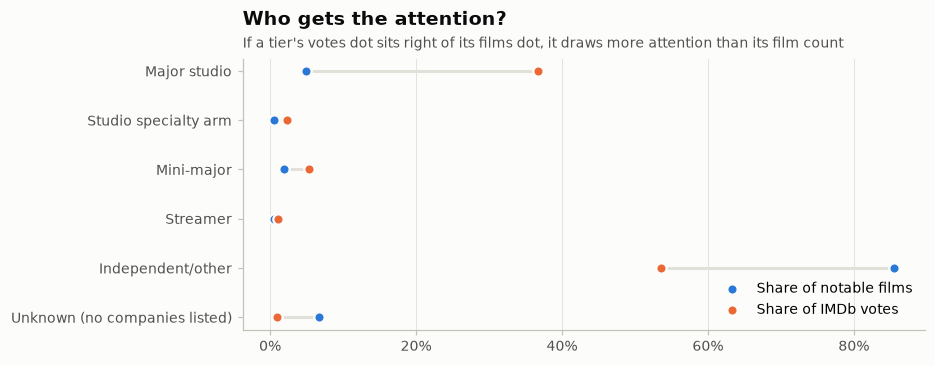

In [342]:
att = tier_summary[["share_of_films", "share_of_votes"]].iloc[::-1]
dot_compare(att, ["share_of_films", "share_of_votes"], ["Share of notable films", "Share of IMDb votes"],
            "Who gets the attention?", "If a tier's votes dot sits right of its films dot, it draws more attention than its film count")
save(plt.gcf(), "12_attention_share"); plt.show()

Most-voted indie film per year (Independent/other; notable films only)


,title,imdb_votes,imdb_rating,runtime,primary_genre,companies
year,,,,,,
2016,Arrival,"887,107",7.9,116,Drama,"FilmNation Entertainment, Lava Bear Films"
2017,Get Out,"846,745",7.8,104,Mystery,"Monkeypaw Productions, Blumhouse Productions"
2018,Green Book,"712,198",8.2,130,Drama,"Participant, DreamWorks Pictures"
2019,Parasite,"1,209,613",8.5,133,Comedy,Barunson E&A
2020,The Gentlemen,"472,851",7.8,113,Comedy,"Miramax, Toff Guy Films"
2021,Dune,"1,103,333",8.0,155,Science Fiction,Legendary Pictures
2022,Everything Everywhere All at Once,"666,664",7.7,140,Action,"IAC Films, AGBO"
2023,The Holdovers,"276,547",7.9,133,Drama,"Miramax, Gran Via Productions"
2024,Dune: Part Two,"807,116",8.4,167,Science Fiction,Legendary Pictures


Runtime per year (minutes) and number of films


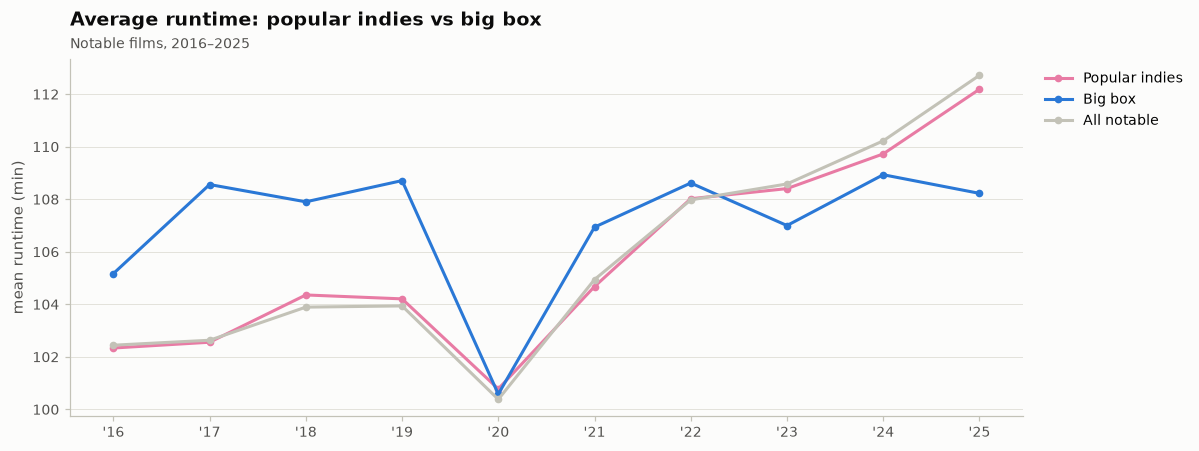

In [343]:
# Popular "indies"
INDIE_TIERS = ["Independent/other"] # add "Studio specialty arm" to count Focus, Searchlight, etc. as indie
indie = nb[nb["studio_tier"].isin(INDIE_TIERS)]

# Most-voted indie film of each year
top_indie = (indie.sort_values(["year", "imdb_votes", "id"], ascending=[True, False, True])
                  .groupby("year").head(1)
                  .assign(companies=lambda d: d["production_companies"].fillna("–").str.split(LIST_SEP).str[:2].str.join(", "))
                  [["year", "title", "imdb_votes", "imdb_rating", "runtime", "primary_genre", "companies"]]
                  .set_index("year"))
print(f"Most-voted indie film per year ({', '.join(INDIE_TIERS)}; notable films only)")
display(top_indie.style.format({"imdb_votes": "{:,.0f}", "imdb_rating": "{:.1f}", "runtime": "{:.0f}"}, na_rep="–"))

# Average runtime of popular indies per year
groups = {"Popular indies": indie, "Big box": nb[nb["big_box"]], "All notable": nb}
rt_year = pd.concat({name: g.groupby("year")["runtime"].agg(["mean", "median", "size"]) for name, g in groups.items()}, axis=1)
print("Runtime per year (minutes) and number of films")
display(rt_year.style.format("{:.0f}", na_rep="–"))

full_years = [y for y in rt_year.index if y <= LAST_FULL_YEAR]
fig, ax = plt.subplots(figsize=(11, 4.2))
for (name, color) in zip(groups, [TIER_COLORS["Independent/other"], TIER_COLORS["Major studio"], AXIS]):
    s = rt_year.loc[full_years, (name, "mean")]
    ax.plot(s.index, s.values, color=color, marker="o", markersize=4, lw=2, label=name)
ax.set_xticks(full_years, [f"'{str(y)[2:]}" for y in full_years]); ax.set_ylabel("mean runtime (min)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
titles(ax, "Average runtime: popular indies vs big box", f"Notable films, {START_YEAR}–{LAST_FULL_YEAR}")
plt.tight_layout(); save(fig, "12_indie_runtime_by_year"); plt.show()

IMDb ratings by group


,films,mean IMDb,median IMDb,middle 50%,% rated ≥ 7,mean TMDB
All notable,"18,055",6.09,6.3,5.4–6.9,24%,6.24
"Popular (≥ 25,000 votes)","2,151",6.54,6.6,6.0–7.2,34%,6.74
Big box,885,6.25,6.3,5.7–6.8,22%,6.73
Indie,"15,430",6.09,6.3,5.4–6.9,24%,6.24
Popular big box,571,6.43,6.5,5.9–7.0,27%,6.77
Popular indie,"1,354",6.60,6.7,6.1–7.3,38%,6.72


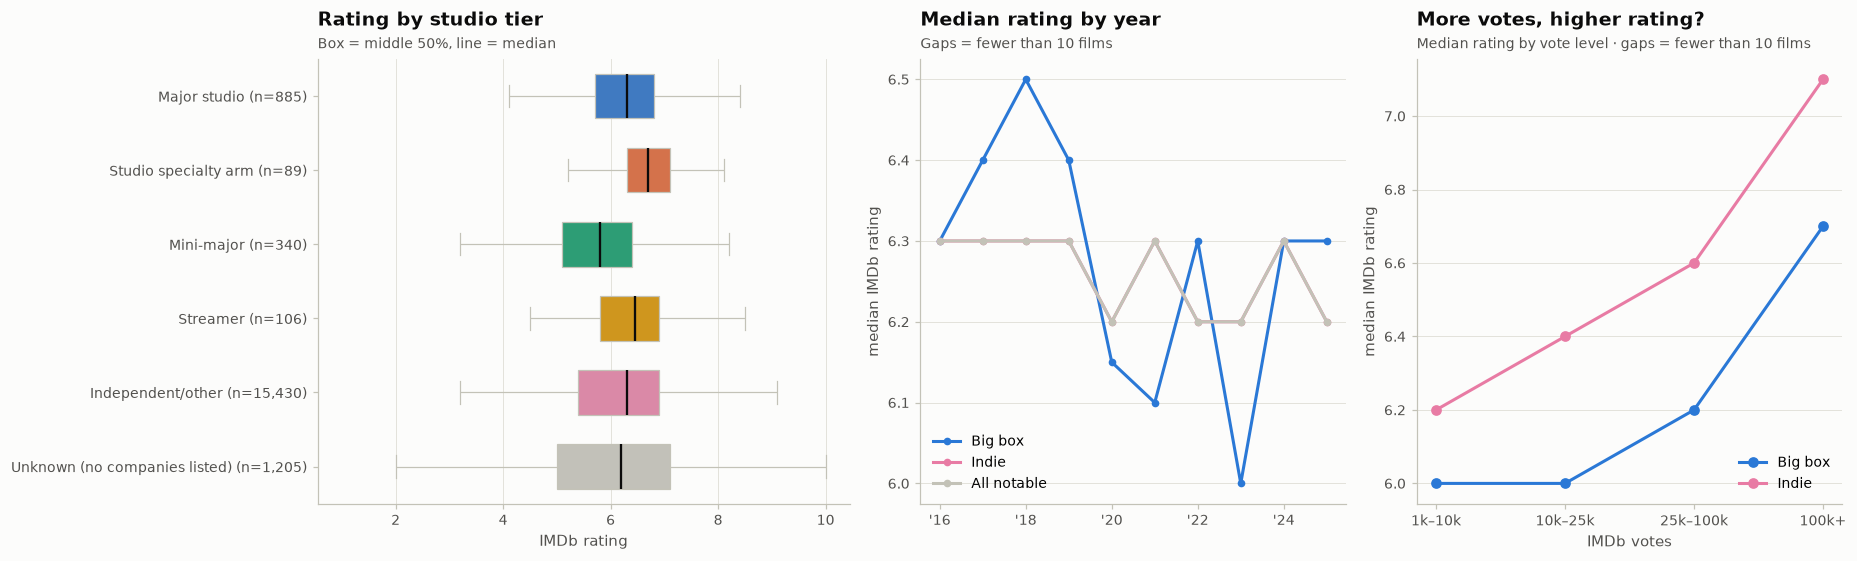

Highest-rated popular indie films (≥ 25,000 votes)


title,year,imdb_rating,imdb_votes,runtime,primary_genre
You Can See Everything,2026,9.0,"35,891",175,Documentary
Attack on Titan: THE LAST ATTACK,2024,8.9,"40,835",145,Animation
David Attenborough: A Life on Our Planet,2020,8.9,"36,554",83,Documentary
Mirror Game,2016,8.8,"31,233",144,Crime
Satluj,2026,8.7,"107,065",164,Crime
Jai Bhim,2021,8.6,"237,511",164,Crime
12th Fail,2023,8.6,"179,928",146,Drama
Soorarai Pottru,2020,8.6,"133,570",149,Drama
20 Days in Mariupol,2023,8.6,"66,154",94,Documentary
Rocketry: The Nambi Effect,2022,8.6,"63,009",154,Drama


Highest-rated popular big box films (≥ 25,000 votes)


title,year,imdb_rating,imdb_votes,runtime,primary_genre
Spider-Man: Across the Spider-Verse,2023,8.5,"563,007",140,Animation
Avengers: Endgame,2019,8.4,"1,509,163",181,Adventure
Avengers: Infinity War,2018,8.4,"1,425,064",149,Adventure
Spider-Man: Into the Spider-Verse,2018,8.4,"825,135",117,Animation
Coco,2017,8.4,"735,594",105,Family
The Odyssey,2026,8.4,"572,992",173,Adventure
Joker,2019,8.3,"1,737,623",122,Crime
Oppenheimer,2023,8.2,"1,113,094",181,Drama
Top Gun: Maverick,2022,8.2,"913,763",131,Action
Spider-Man: No Way Home,2021,8.1,"1,089,117",148,Action


,title,year,imdb_rating,imdb_votes,vote_average,vote_count
71794,Ant-Man and the Wasp: Quantumania,2023,6.000,"283,306.000",6.194,"6,266.000"
233180,Marvel Studios Assembled: The Making of Ant-Ma...,2023,6.800,214.000,6.200,20.000


In [344]:
# Rating exploration: big box vs indie
POPULAR_MIN_VOTES = 25_000
GOOD = 7.0
MIN_N = 10
# Find the independent tier's label
INDIE_LABEL = next(t for t in nb["studio_tier"].unique() if t.replace(" ", "").lower() == "independent/other")

r = nb.dropna(subset=["imdb_rating"]).copy()
r["popular"] = r["imdb_votes"] >= POPULAR_MIN_VOTES
r["group"] = np.select([r["big_box"], r["studio_tier"] == INDIE_LABEL], ["Big box", "Indie"], default="Other tiers")
COL = {"Big box": TIER_COLORS["Major studio"], "Indie": TIER_COLORS.get(INDIE_LABEL, SERIES[4]), "All notable": AXIS}

# Summary table 
segments = {"All notable": r, f"Popular (≥ {POPULAR_MIN_VOTES:,} votes)": r[r["popular"]],
            "Big box": r[r["group"] == "Big box"], "Indie": r[r["group"] == "Indie"],
            "Popular big box": r[(r["group"] == "Big box") & r["popular"]],
            "Popular indie": r[(r["group"] == "Indie") & r["popular"]]}
summary = pd.DataFrame({name: {
    "films": len(s),
    "mean IMDb": s["imdb_rating"].mean(),
    "median IMDb": s["imdb_rating"].median(),
    "middle 50%": f"{s['imdb_rating'].quantile(.25):.1f}–{s['imdb_rating'].quantile(.75):.1f}" if len(s) else "–",
    f"% rated ≥ {GOOD:g}": (s["imdb_rating"] >= GOOD).mean() if len(s) else np.nan,
    "mean TMDB": s["vote_average"].mean(),
} for name, s in segments.items()}).T
print("IMDb ratings by group")
display(summary.style.format({"films": "{:,.0f}", "mean IMDb": "{:.2f}", "median IMDb": "{:.1f}",
                              f"% rated ≥ {GOOD:g}": "{:.0%}", "mean TMDB": "{:.2f}"}, na_rep="–"))

# Charts 
present = list(r["studio_tier"].unique())
tiers = [t for t in TIER_ORDER if t in present] + [t for t in present if t not in TIER_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.25, 1, 1]})

# a) rating spread by studio tier
sns.boxplot(data=r, y="studio_tier", x="imdb_rating", order=tiers, hue="studio_tier",
            palette={t: TIER_COLORS.get(t, AXIS) for t in tiers}, legend=False, ax=axes[0], **BOX_KW)
n_t = r["studio_tier"].value_counts()
axes[0].set_yticks(range(len(tiers)), [f"{t} (n={n_t[t]:,})" for t in tiers])
axes[0].set_xlabel("IMDb rating"); axes[0].set_ylabel(""); axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False)
titles(axes[0], "Rating by studio tier", "Box = middle 50%, line = median")

# b) median rating per year
full = r[r["year"] <= LAST_FULL_YEAR]
for name, sub in [("Big box", full[full["group"] == "Big box"]), ("Indie", full[full["group"] == "Indie"]), ("All notable", full)]:
    g = sub.groupby("year")["imdb_rating"]
    med = g.median().where(g.size() >= MIN_N)
    axes[1].plot(med.index, med.values, color=COL[name], marker="o", markersize=4, lw=2, label=name)
axes[1].set_xticks(YEARS_FULL[::2], [f"'{str(y)[2:]}" for y in YEARS_FULL[::2]])
axes[1].set_ylabel("median IMDb rating"); axes[1].legend(loc="lower left")
titles(axes[1], "Median rating by year", f"Gaps = fewer than {MIN_N} films")

# c) does popularity go with higher ratings?
buckets = ["1k–10k", "10k–25k", "25k–100k", "100k+"]
r["vote_bucket"] = pd.cut(r["imdb_votes"], [1e3, 1e4, 2.5e4, 1e5, np.inf], labels=buckets, right=False)
for name in ["Big box", "Indie"]:
    g = r[r["group"] == name].groupby("vote_bucket", observed=False)["imdb_rating"]
    med = g.median().where(g.size() >= MIN_N).reindex(buckets)
    axes[2].plot(range(len(buckets)), med.values, color=COL[name], marker="o", markersize=6, lw=2, label=name)
axes[2].set_xticks(range(len(buckets)), buckets); axes[2].set_xlabel("IMDb votes")
axes[2].set_ylabel("median IMDb rating"); axes[2].legend(loc="lower right")
titles(axes[2], "More votes, higher rating?", f"Median rating by vote level · gaps = fewer than {MIN_N} films")
plt.tight_layout(); save(fig, "11_rating_groups"); plt.show()

# Highest-rated popular films in each group
cols = ["title", "year", "imdb_rating", "imdb_votes", "runtime", "primary_genre"]
fmt = {"imdb_rating": "{:.1f}", "imdb_votes": "{:,.0f}", "runtime": "{:.0f}"}
for name in ["Indie", "Big box"]:
    top = r[(r["group"] == name) & r["popular"]].sort_values(["imdb_rating", "imdb_votes"], ascending=False).head(10)
    print(f"Highest-rated popular {name.lower()} films (≥ {POPULAR_MIN_VOTES:,} votes)")
    display(top[cols].style.format(fmt).hide(axis="index"))
    
df.loc[df["title"].str.contains("Quantumania", case=False, na=False), ["title", "year", "imdb_rating", "imdb_votes", "vote_average", "vote_count"]]

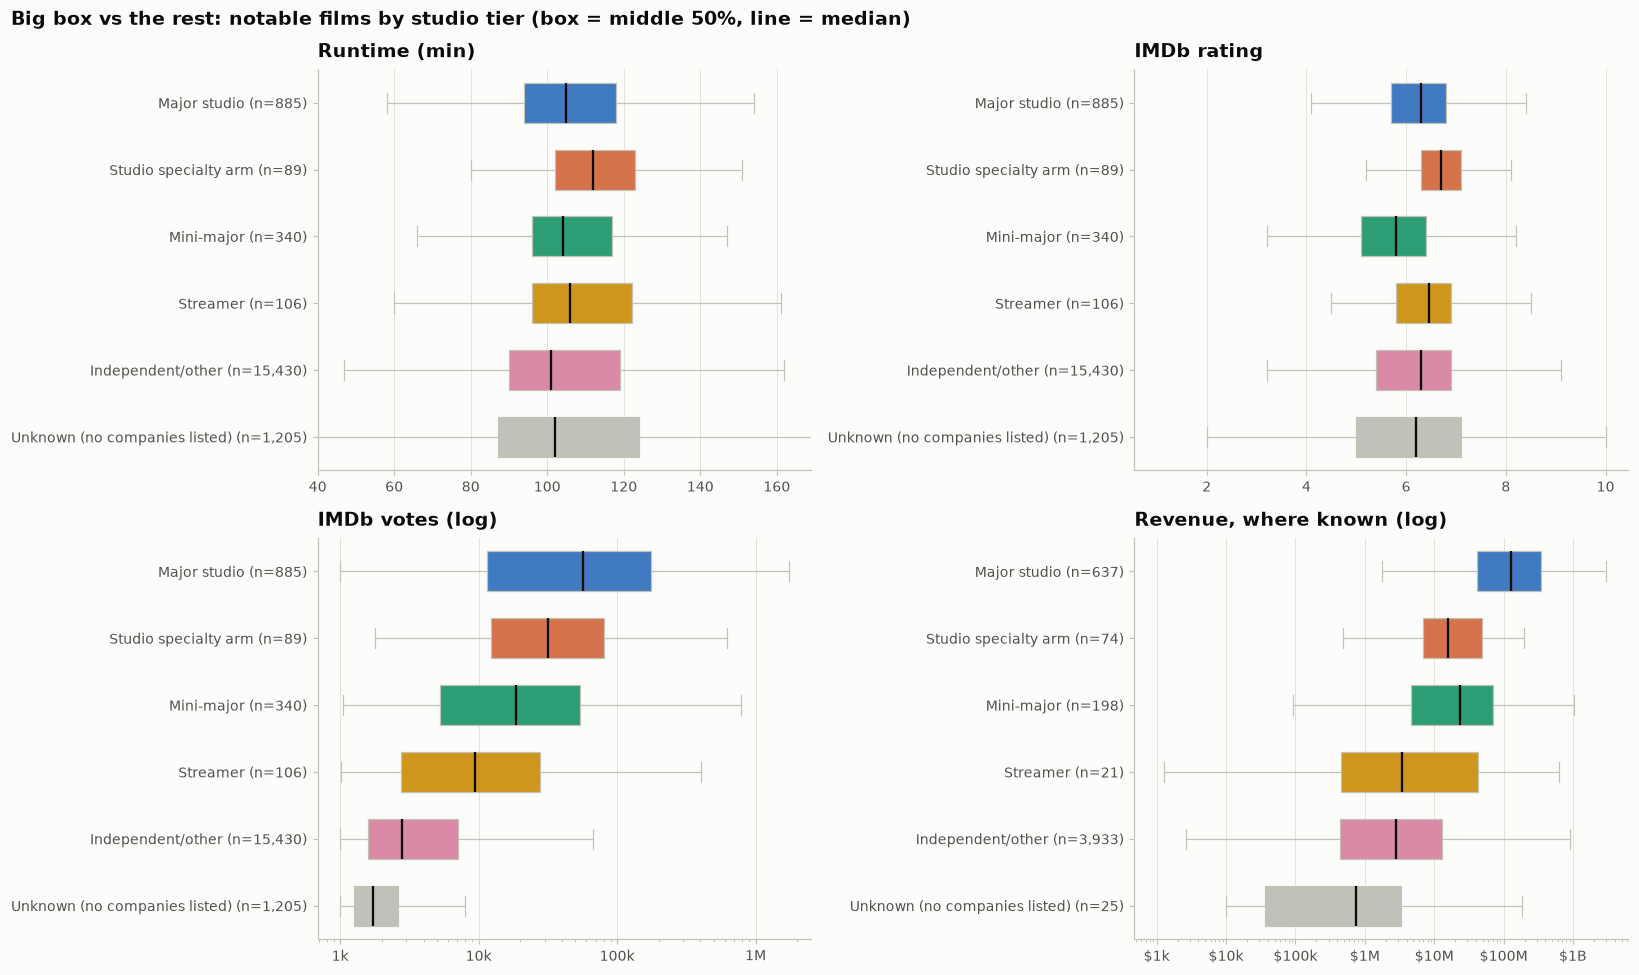

In [345]:
tiers_present = [t for t in TIER_ORDER if t in set(nb["studio_tier"])]
metrics = [("runtime", "Runtime (min)", False, None), ("imdb_rating", "IMDb rating", False, None),
           ("imdb_votes", "IMDb votes (log)", True, HUMAN), ("revenue", "Revenue, where known (log)", True, MONEY)]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (col, lab, logx, fmt) in zip(axes.flat, metrics):
    d = nb[["studio_tier", col]].dropna()
    sns.boxplot(data=d, y="studio_tier", x=col, order=tiers_present, hue="studio_tier", palette=TIER_COLORS,
                legend=False, ax=ax, log_scale=logx, **BOX_KW)
    if fmt is not None:
        ax.xaxis.set_major_formatter(fmt)
    if col == "runtime":
        ax.set_xlim(FEATURE_MIN_RUNTIME, d[col].quantile(0.99))
    n = d.groupby("studio_tier").size().reindex(tiers_present).fillna(0).astype(int)
    ax.set_yticks(range(len(tiers_present)), [f"{t} (n={n[t]:,})" for t in tiers_present])
    ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    titles(ax, lab)
fig.suptitle("Big box vs the rest: notable films by studio tier (box = middle 50%, line = median)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "12_tier_distributions"); plt.show()

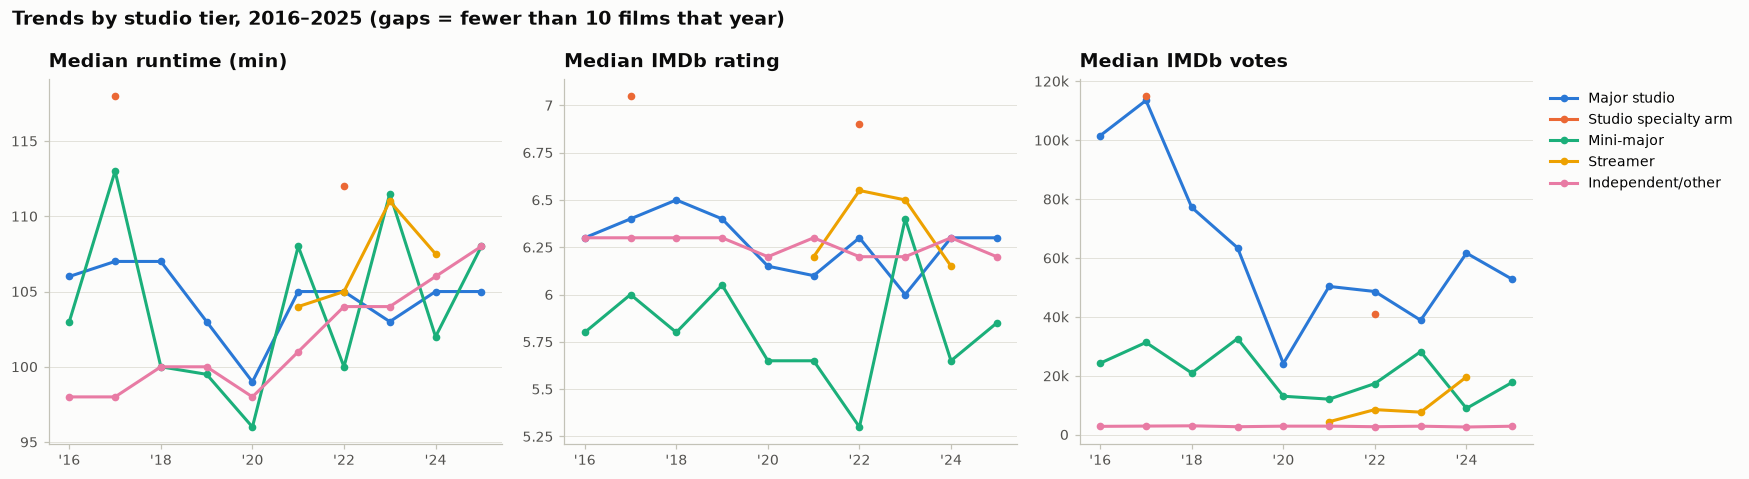

Note: median votes fall for recent years in every tier, because newer films have had less time to collect votes.


In [346]:
main_tiers = [t for t in tiers_present if t != "Unknown (no companies listed)"]
full = nb[nb["year"] <= LAST_FULL_YEAR]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (col, lab) in zip(axes, [("runtime", "Median runtime (min)"),
                                 ("imdb_rating", "Median IMDb rating"),
                                 ("imdb_votes", "Median IMDb votes")]):
    grp = full.groupby(["year", "studio_tier"])[col]
    med = grp.median().unstack().where(grp.count().unstack() >= 10)
    for t in main_tiers:
        if t in med and med[t].notna().any():
            ax.plot(med.index, med[t], color=TIER_COLORS[t], lw=2, marker="o", markersize=4, label=t)
    ax.yaxis.set_major_formatter(HUMAN)
    ax.set_xticks(med.index[::2], [f"'{str(y)[2:]}" for y in med.index[::2]])
    titles(ax, lab)
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle(f"Trends by studio tier, {START_YEAR}–{LAST_FULL_YEAR} (gaps = fewer than 10 films that year)", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "12_tier_trends"); plt.show()
print("Note: median votes fall for recent years in every tier, because newer films have had less time to collect votes.")

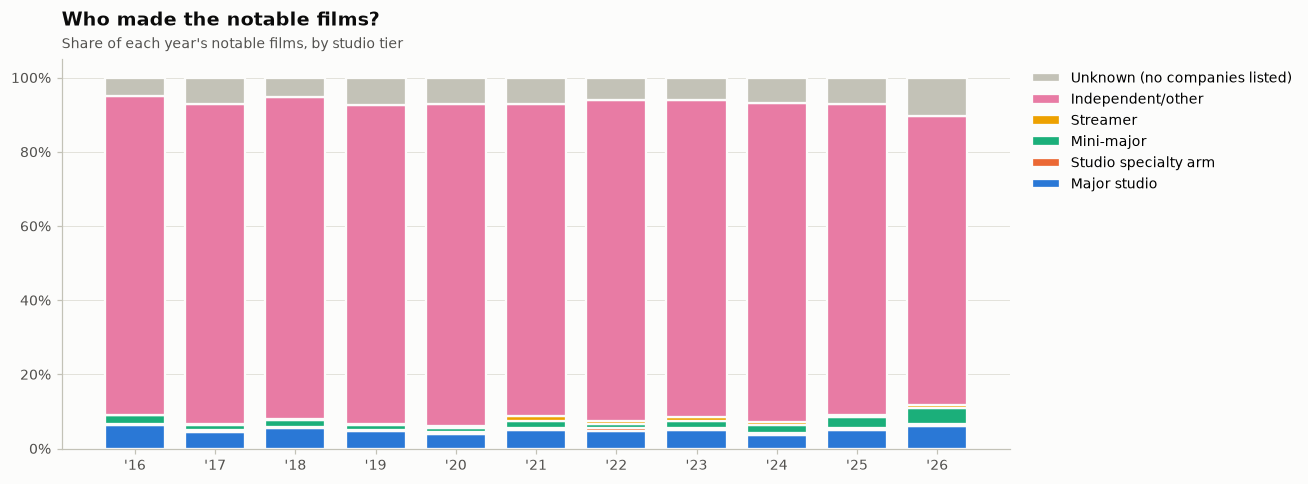

In [347]:
ty = (nb.groupby(["year", "studio_tier"]).size().unstack(fill_value=0)
        .reindex(columns=tiers_present, fill_value=0))
ty = ty.div(ty.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 4.5))
bottom = np.zeros(len(ty))
for t in tiers_present:
    ax.bar(ty.index, ty[t], bottom=bottom, color=TIER_COLORS[t], width=0.75, label=t, edgecolor=SURFACE, linewidth=1.5)
    bottom += ty[t].values
ax.yaxis.set_major_formatter(PCT); ax.set_xticks(ty.index, [f"'{str(y)[2:]}" for y in ty.index])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
titles(ax, "Who made the notable films?", "Share of each year's notable films, by studio tier")
plt.tight_layout(); save(fig, "12_tier_share_by_year"); plt.show()

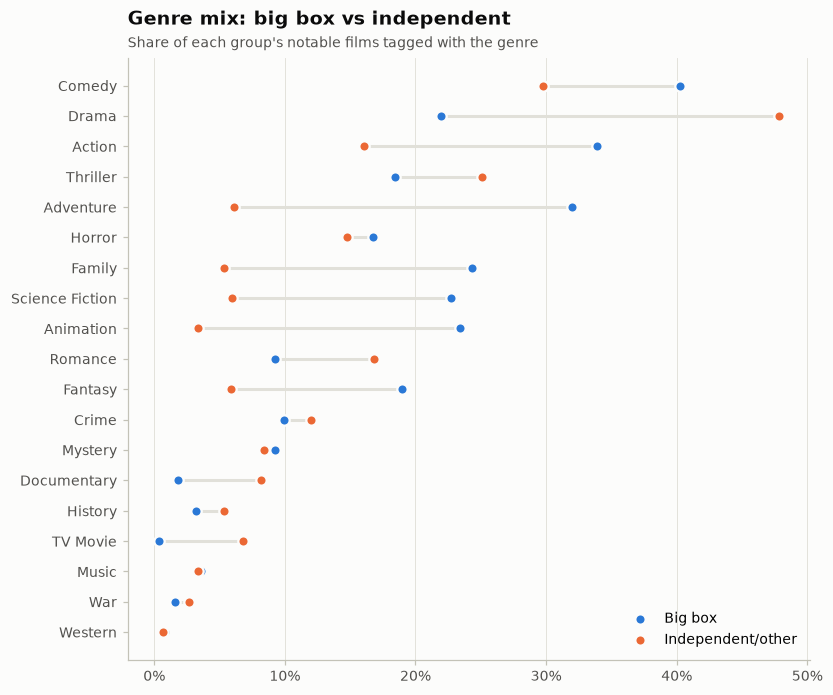

Most-watched big box films (by IMDb votes)


,title,year,runtime,imdb_rating,imdb_votes,revenue
22650,Joker,2019,122.000,8.300,"1,737,623.000","1,078,958,629.000"
613,Avengers: Endgame,2019,181.000,8.400,"1,509,163.000","2,942,649,778.000"
614,Avengers: Infinity War,2018,149.000,8.400,"1,425,064.000","2,052,415,039.000"
558,Deadpool,2016,108.000,8.000,"1,279,433.000","782,837,347.000"
148194,Oppenheimer,2023,181.000,8.200,"1,113,094.000","952,000,000.000"
69590,Spider-Man: No Way Home,2021,148.000,8.100,"1,089,117.000","1,921,426,073.000"
20296,Once Upon a Time in... Hollywood,2019,162.000,7.600,"987,023.000","393,869,691.000"
8287,The Batman,2022,177.000,7.800,"958,494.000","772,775,278.000"
393,Captain America: Civil War,2016,147.000,7.800,"957,730.000","1,155,046,416.000"
342,Logan,2017,137.000,8.100,"947,532.000","619,021,436.000"


Audit: most common companies left in 'Independent/other'. Add any studio labels you spot to STUDIO_TIERS.
production_companies
Hallmark Media                           286
France 2 Cinéma                          152
ARTE France Cinéma                       144
Film i Väst                              129
France 3 Cinéma                          127
Front Street Pictures                    116
RAI Cinema                               115
TOHO                                     113
T-Series                                 109
StudioCanal                              102
Voltage Pictures                         100
ARTE                                      94
Lighthouse Pictures                       94
Zee Studios                               94
BBC Film                                  93
Head Gear Films                           90
Motion Picture Corporation of America     90
uMedia                                    89
XYZ Films                                 86
A24               

In [348]:
gmix = pd.DataFrame({"big box": share_with(bb, "genres"), "independent": share_with(ind, "genres")}).fillna(0)
gmix = gmix.loc[(gmix["big box"] + gmix["independent"]).sort_values().index]
dot_compare(gmix, ["big box", "independent"], ["Big box", "Independent/other"],
            "Genre mix: big box vs independent", "Share of each group's notable films tagged with the genre")
save(plt.gcf(), "12_tier_genre_mix"); plt.show()

print("Most-watched big box films (by IMDb votes)")
display(bb.nlargest(15, "imdb_votes")[["title", "year", "runtime", "imdb_rating", "imdb_votes", "revenue"]])

print("Audit: most common companies left in 'Independent/other'. Add any studio labels you spot to STUDIO_TIERS.")
print(explode_list(ind, "production_companies", keep=("id",))["production_companies"].value_counts().head(25).to_string())

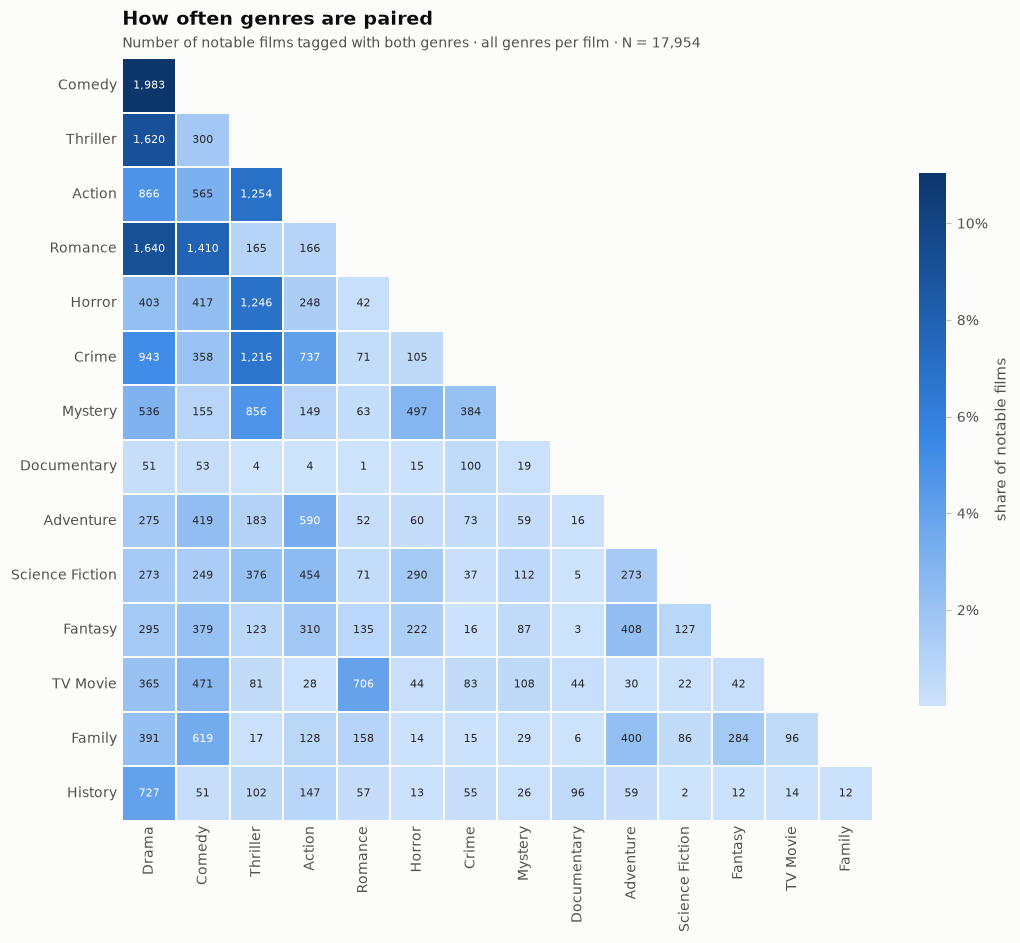

Most common genre pairs (lift > 1: paired more often than if genres were assigned independently)


pair,films,% of films,lift
Comedy + Drama,"1,983",11.0%,0.79
Drama + Romance,"1,640",9.1%,1.20
Drama + Thriller,"1,620",9.0%,0.79
Comedy + Romance,"1,410",7.9%,1.55
Action + Thriller,"1,254",7.0%,1.64
Horror + Thriller,"1,246",6.9%,1.91
Crime + Thriller,"1,216",6.8%,2.26
Crime + Drama,943,5.3%,0.95
Action + Drama,866,4.8%,0.62
Mystery + Thriller,856,4.8%,2.30


Most common exact combinations (all genres per film); films with a single genre appear on their own


,films,% of films
genres,,
Drama,"1,627",9.1%
Comedy,944,5.3%
Comedy + Drama,914,5.1%
Documentary,852,4.7%
Drama + Romance,613,3.4%
Horror + Thriller,500,2.8%
Comedy + Romance,457,2.5%
Horror,446,2.5%
Drama + Thriller,439,2.4%


Genres per film: {1: 4358, 2: 6688, 3: 5178, 4: 1356, 5: 316, 6: 50, 7: 7, 8: 1}


In [349]:
# Common genre pairings
GENRE_LIMIT = None 
TOP_GENRES = 15

films_g = nb[["id", "genres"]].dropna()
glists = films_g["genres"].str.split(LIST_SEP).apply(lambda gs: list(dict.fromkeys(g.strip() for g in gs[:GENRE_LIMIT])))
N = len(glists)

long = glists.explode()
onehot = pd.crosstab(long.index, long).clip(upper=1)
co = onehot.T @ onehot 
top = onehot.sum().sort_values(ascending=False).index[:TOP_GENRES]
co_top = co.loc[top, top]

# Pair matrix
co_plot = co_top.iloc[1:, :-1]
mask = np.triu(np.ones_like(co_plot, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(co_plot / N, mask=mask, cmap=SEQ, annot=co_plot, fmt=",d", annot_kws={"size": 7.5},
            linewidths=1, linecolor=SURFACE, ax=ax, cbar_kws={"label": "share of notable films", "format": PCT, "shrink": 0.7})
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(length=0); ax.grid(False)
limit_txt = "all genres per film" if GENRE_LIMIT is None else f"first {GENRE_LIMIT} genres per film"
titles(ax, "How often genres are paired", f"Number of notable films tagged with both genres · {limit_txt} · N = {N:,}")
save(fig, "13_genre_pairs_matrix"); plt.show()

# Most common pairs
share = onehot.mean()
upper = co.where(np.triu(np.ones(co.shape, dtype=bool), k=1))
pairs = (upper.rename_axis(index="genre_a", columns="genre_b").stack().rename("films").reset_index()
              .dropna(subset=["films"]).astype({"films": int}))
pairs = pairs[pairs["films"] > 0]
pairs["pair"] = pairs["genre_a"] + " + " + pairs["genre_b"]
pairs["% of films"] = pairs["films"] / N
pairs["lift"] = pairs["% of films"] / (pairs["genre_a"].map(share) * pairs["genre_b"].map(share))
print("Most common genre pairs (lift > 1: paired more often than if genres were assigned independently)")
display(pairs.sort_values("films", ascending=False).head(15)[["pair", "films", "% of films", "lift"]]
             .style.format({"films": "{:,}", "% of films": "{:.1%}", "lift": "{:.2f}"}).hide(axis="index"))

# Most common exact genre combinations (the film's whole genre list)
combos = glists.apply(lambda gs: " + ".join(sorted(gs))).value_counts()
print(f"Most common exact combinations ({limit_txt}); films with a single genre appear on their own")
display(pd.DataFrame({"films": combos, "% of films": combos / N}).head(15)
          .style.format({"films": "{:,}", "% of films": "{:.1%}"}))
print("Genres per film:", glists.str.len().value_counts().sort_index().to_dict())

## Step 10: Relationships between variables

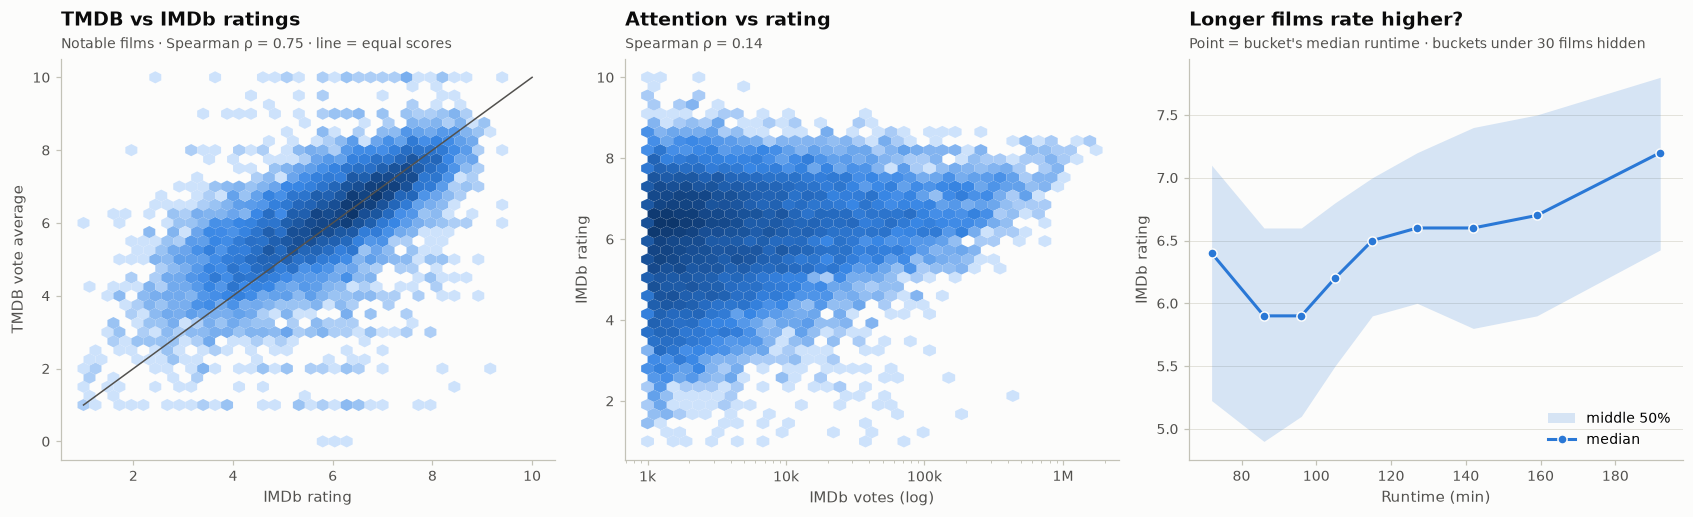

In [350]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

r = nb[["vote_average", "imdb_rating"]].dropna()
hb = axes[0].hexbin(r["imdb_rating"], r["vote_average"], gridsize=35, cmap=SEQ, mincnt=1, bins="log")
axes[0].plot([1, 10], [1, 10], color=INK_2, lw=1)
axes[0].set_xlabel("IMDb rating"); axes[0].set_ylabel("TMDB vote average"); axes[0].grid(False)
titles(axes[0], "TMDB vs IMDb ratings", f"Notable films · Spearman ρ = {r.corr('spearman').iloc[0,1]:.2f} · line = equal scores")

q = nb[["imdb_votes", "imdb_rating"]].dropna()
axes[1].hexbin(q["imdb_votes"], q["imdb_rating"], gridsize=35, cmap=SEQ, mincnt=1, bins="log", xscale="log")
axes[1].xaxis.set_major_formatter(HUMAN); axes[1].grid(False)
axes[1].set_xlabel("IMDb votes (log)"); axes[1].set_ylabel("IMDb rating")
titles(axes[1], "Attention vs rating", f"Spearman ρ = {q.corr('spearman').iloc[0,1]:.2f}")

RT_CAP, MIN_N = 240, 30
rt = nb.loc[nb["runtime"].between(FEATURE_MIN_RUNTIME, RT_CAP), ["runtime", "imdb_rating"]].dropna()
rt["bucket"] = pd.cut(rt["runtime"], bins=[40, 80, 90, 100, 110, 120, 135, 150, 180, RT_CAP], include_lowest=True)
s = (rt.groupby("bucket", observed=True)
       .agg(x=("runtime", "median"), med=("imdb_rating", "median"),
            q1=("imdb_rating", lambda v: v.quantile(.25)), q3=("imdb_rating", lambda v: v.quantile(.75)),
            n=("imdb_rating", "size")))
s = s[s["n"] >= MIN_N]
axes[2].fill_between(s["x"], s["q1"], s["q3"], color=BLUE, alpha=0.18, linewidth=0, label="middle 50%")
axes[2].plot(s["x"], s["med"], color=BLUE, marker="o", markersize=6, markeredgecolor=SURFACE, label="median")
axes[2].set_xlabel("Runtime (min)"); axes[2].set_ylabel("IMDb rating"); axes[2].legend(loc="lower right")
titles(axes[2], "Longer films rate higher?",
       f"Point = bucket's median runtime · buckets under {MIN_N} films hidden")
plt.tight_layout(); save(fig, "10_ratings"); plt.show()

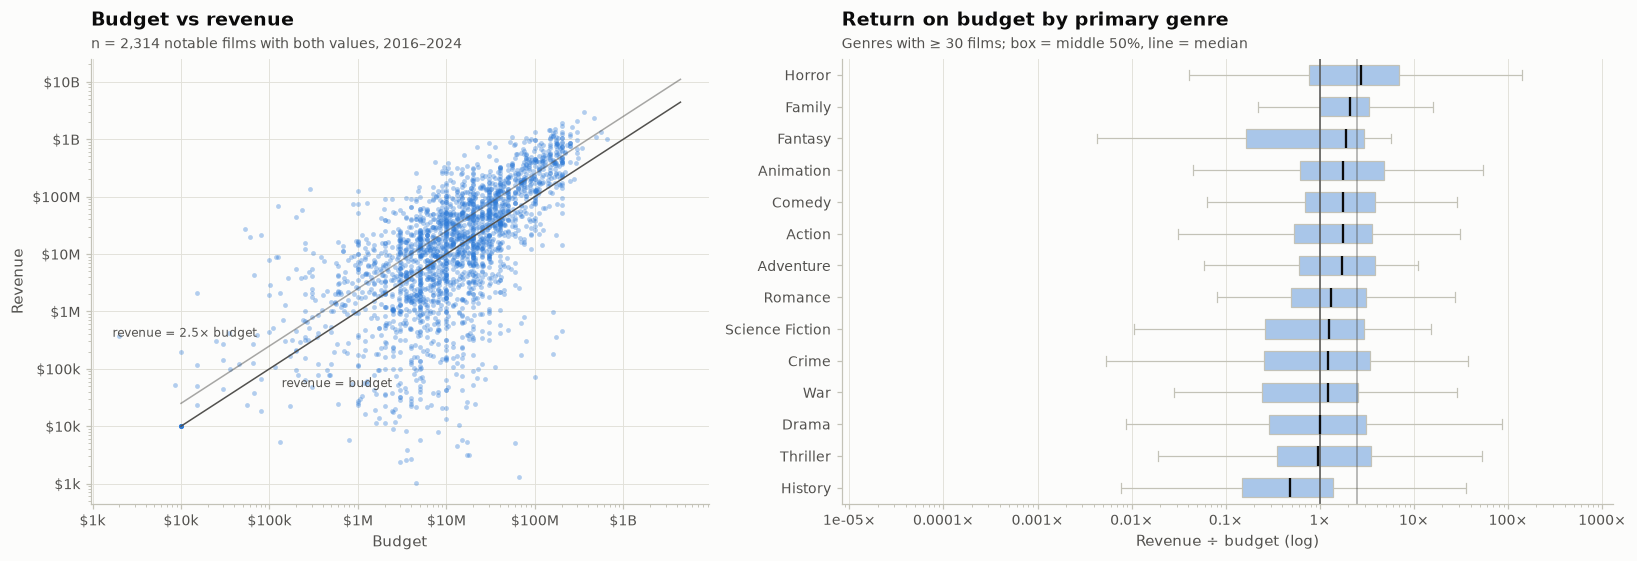

Share of films with revenue below 1× budget: 40.3% | below 2.5×: 64.3%


In [351]:
fin = nb[nb["budget"].notna() & nb["revenue"].notna() & (nb["year"] < LAST_FULL_YEAR)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].scatter(fin["budget"], fin["revenue"], s=10, color=BLUE, alpha=0.35, linewidth=0)
lim = np.array([1e4, max(fin["budget"].max(), fin["revenue"].max(), 1e5) * 1.5])
axes[0].plot(lim, lim, color=INK_2, lw=1); axes[0].plot(lim, 2.5 * lim, color=INK_2, lw=1, alpha=0.5)
axes[0].annotate("revenue = budget", (1e5, 1e5), xytext=(8, -12), textcoords="offset points", fontsize=8, color=INK_2)
axes[0].annotate("revenue = 2.5× budget", (1e5, 2.5e5), xytext=(-8, 6), textcoords="offset points", fontsize=8, color=INK_2, ha="right")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].xaxis.set_major_formatter(MONEY); axes[0].yaxis.set_major_formatter(MONEY)
axes[0].set_xlabel("Budget"); axes[0].set_ylabel("Revenue"); axes[0].grid(True, axis="both")
titles(axes[0], "Budget vs revenue", f"n = {len(fin):,} notable films with both values, {START_YEAR}–{LAST_FULL_YEAR-1}")

roi = fin[["primary_genre", "roi"]].dropna()
keep = roi["primary_genre"].value_counts()
keep = keep[keep >= 30].index
roi = roi[roi["primary_genre"].isin(keep)]
order = roi.groupby("primary_genre")["roi"].median().sort_values(ascending=False).index
sns.boxplot(data=roi, y="primary_genre", x="roi", order=order, ax=axes[1], color=BLUE_LIGHT,
            fliersize=0, linewidth=0.8, log_scale=True, width=0.6,
            medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": AXIS}, capprops={"color": AXIS},
            boxprops={"edgecolor": AXIS})
axes[1].axvline(1, color=INK_2, lw=1); axes[1].axvline(2.5, color=INK_2, lw=1, alpha=0.5)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:g}×"))
axes[1].set_xlabel("Revenue ÷ budget (log)"); axes[1].set_ylabel(""); axes[1].grid(axis="x"); axes[1].grid(axis="y", visible=False)
titles(axes[1], "Return on budget by primary genre", "Genres with ≥ 30 films; box = middle 50%, line = median")
plt.tight_layout(); save(fig, "10_money"); plt.show()
print(f"Share of films with revenue below 1× budget: {(fin['roi'] < 1).mean():.1%} | below 2.5×: {(fin['roi'] < 2.5).mean():.1%}")

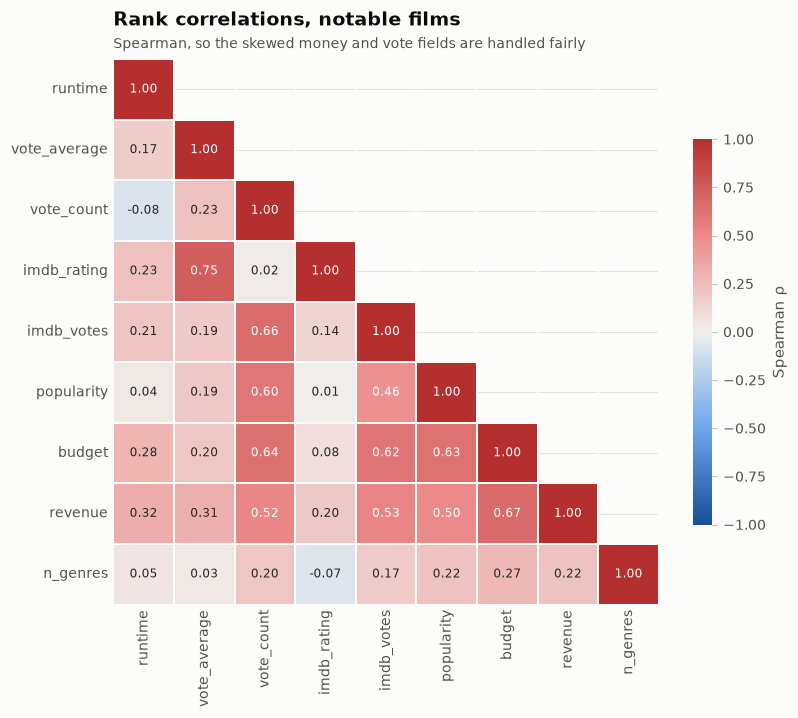

In [352]:
num = nb[["runtime", "vote_average", "vote_count", "imdb_rating", "imdb_votes", "popularity", "budget", "revenue", "n_genres"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1, linecolor=SURFACE, square=True, ax=ax, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"},
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
ax.tick_params(length=0)
titles(ax, "Rank correlations, notable films", "Spearman, so the skewed money and vote fields are handled fairly")
save(fig, "10_corr"); plt.show()

,films,median_imdb,median_votes,budget_known,median_budget,median_roi,share
studio_tier,,,,,,,
Major studio,885,6.300,"57,033.000",0.736,"55,000,000.000",2.521,0.049
Studio specialty arm,89,6.700,"31,621.000",0.663,"20,000,000.000",1.302,0.005
Mini-major,340,5.800,"18,740.500",0.565,"20,000,000.000",1.123,0.019
Streamer,106,6.450,"9,363.000",0.189,"77,500,000.000",0.452,0.006
Independent/other,15430,6.300,"2,804.000",0.184,"6,000,000.000",1.086,0.855
Unknown (no companies listed),1205,6.200,"1,721.000",0.036,"266,103.000",1.769,0.067


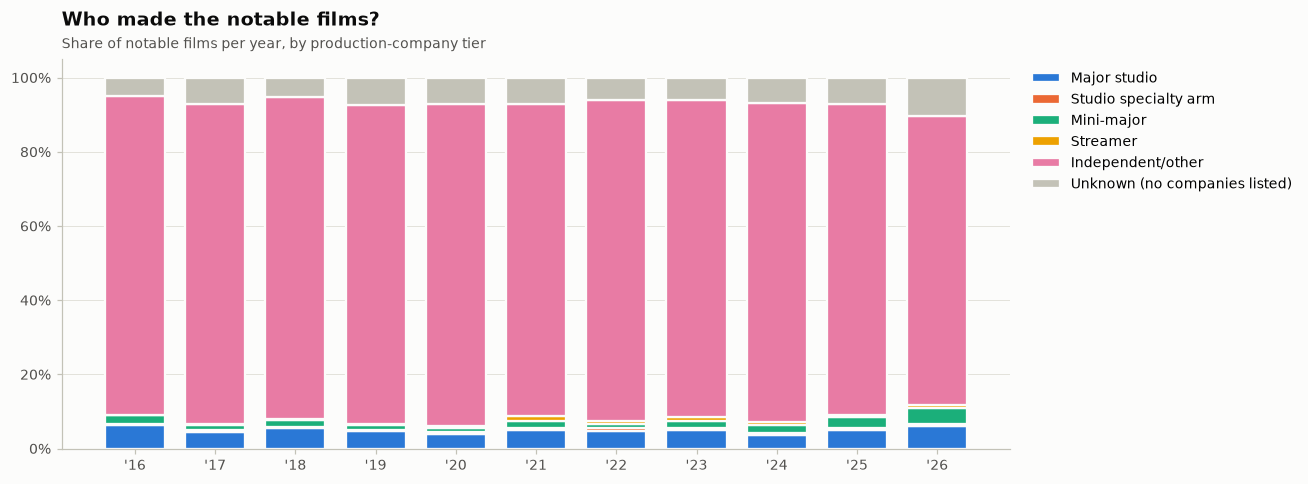

production_companies
Hallmark Media                           286
France 2 Cinéma                          152
ARTE France Cinéma                       144
Film i Väst                              129
France 3 Cinéma                          127
Front Street Pictures                    116
RAI Cinema                               115
TOHO                                     113
T-Series                                 109
StudioCanal                              102
Voltage Pictures                         100
ARTE                                      94
Lighthouse Pictures                       94
Zee Studios                               94
BBC Film                                  93
Head Gear Films                           90
Motion Picture Corporation of America     90
uMedia                                    89
XYZ Films                                 86
A24                                       85
Ingenious Media                           84
BFI                               

In [353]:
TIER_COLORS = dict(zip(TIER_ORDER, SERIES[:5] + [AXIS]))

summary = nb.groupby("studio_tier").agg(
    films=("id", "size"), median_imdb=("imdb_rating", "median"), median_votes=("imdb_votes", "median"),
    budget_known=("budget", lambda s: s.notna().mean()), median_budget=("budget", "median"),
    median_roi=("roi", "median")).reindex(TIER_ORDER)
summary["share"] = summary["films"] / summary["films"].sum()
display(summary)

ty = (nb.groupby(["year", "studio_tier"]).size().unstack(fill_value=0)
        .reindex(columns=TIER_ORDER, fill_value=0))
ty = ty.div(ty.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 4.5))
bottom = np.zeros(len(ty))
for t in TIER_ORDER:
    ax.bar(ty.index, ty[t], bottom=bottom, color=TIER_COLORS[t], width=0.75, label=t,
           edgecolor=SURFACE, linewidth=1.5)
    bottom += ty[t].values
ax.yaxis.set_major_formatter(PCT)
ax.set_xticks(ty.index, [f"'{str(y)[2:]}" for y in ty.index])
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
titles(ax, "Who made the notable films?", "Share of notable films per year, by production-company tier")
plt.tight_layout(); save(fig, "10_studio_tier_by_year"); plt.show()

print(explode_list(nb[nb["studio_tier"] == "Independent/other"], "production_companies", keep=("id",))
      ["production_companies"].value_counts().head(25).to_string())

## Step 11: How the genre mix changes over time

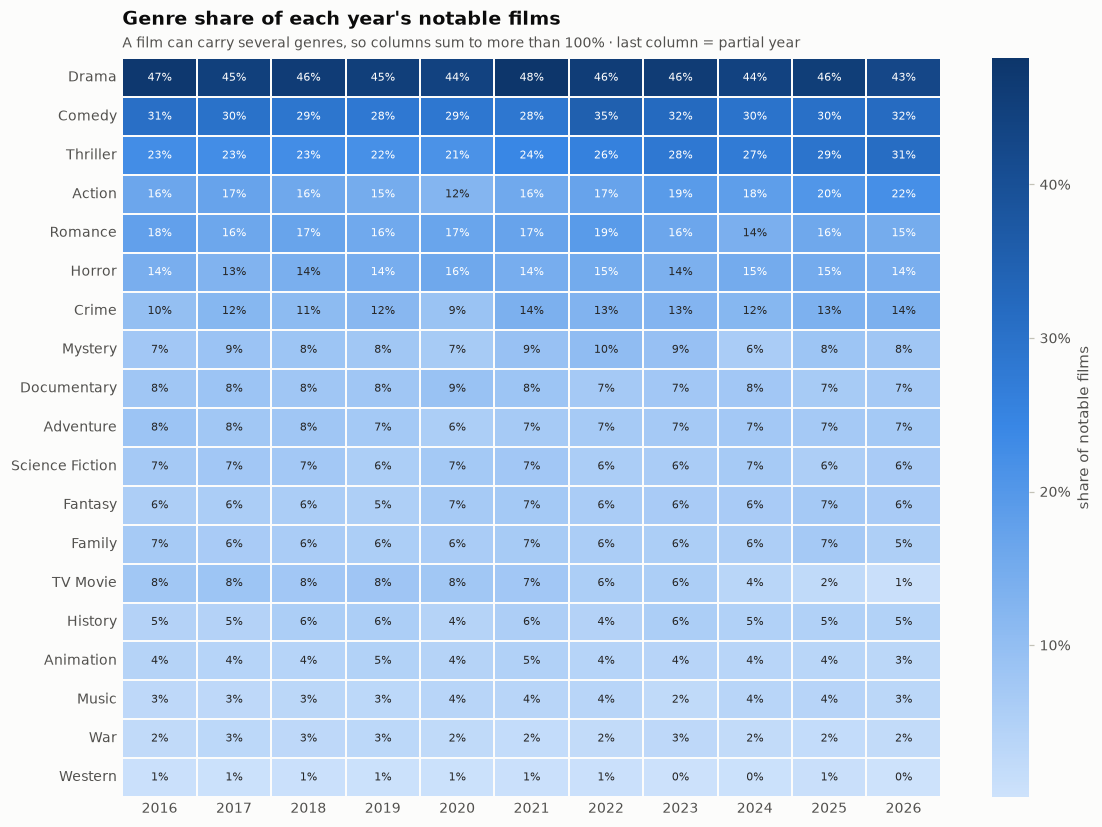

In [354]:
g_long = explode_list(nb, "genres", keep=("id", "year"))
totals = nb.groupby("year").size()
gy = g_long.groupby(["genres", "year"])["id"].nunique().unstack(fill_value=0).div(totals, axis=1)
top_genres = gy.mean(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 0.38 * len(gy) + 1.5))
sns.heatmap(gy.loc[top_genres], cmap=SEQ, annot=True, fmt=".0%", annot_kws={"size": 7.5},
            linewidths=1, linecolor=SURFACE, ax=ax, cbar_kws={"label": "share of notable films", "format": PCT})
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(length=0)
titles(ax, "Genre share of each year's notable films",
       "A film can carry several genres, so columns sum to more than 100%" + (" · last column = partial year" if PARTIAL_YEAR else ""))
save(fig, "11_genre_year_heatmap"); plt.show()

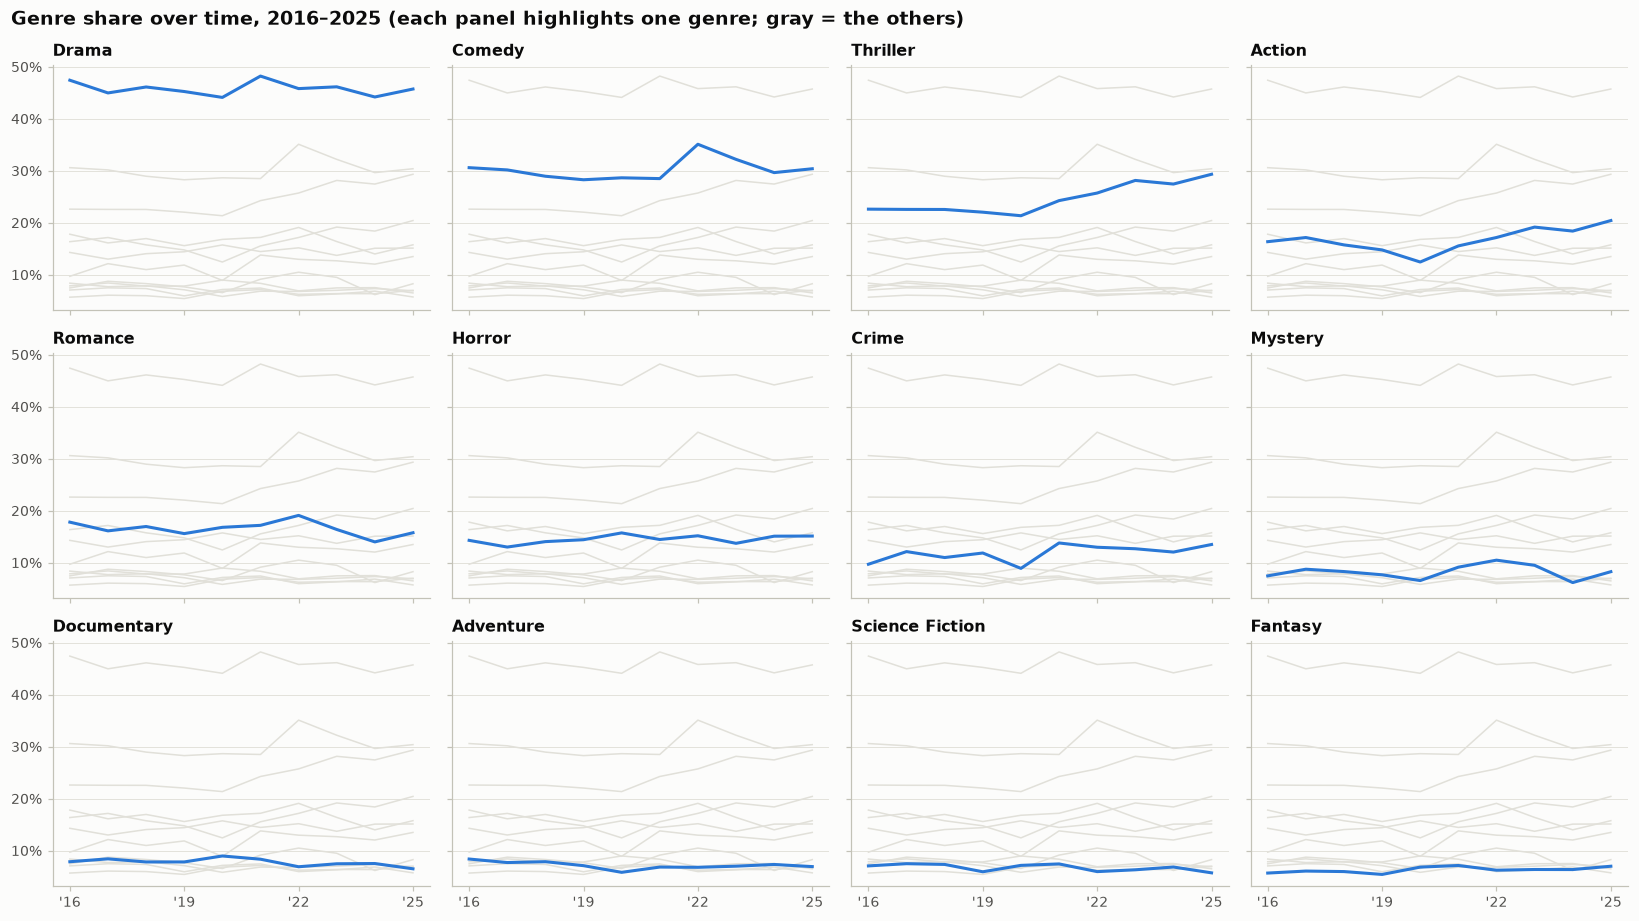

,first_3y,last_3y,change_pts
genres,,,
TV Movie,7.9%,3.9%,-3.9
Romance,17.0%,15.4%,-1.6
Science Fiction,7.3%,6.3%,-1.0
Adventure,8.0%,7.1%,-0.9
Documentary,8.0%,7.2%,-0.9
Drama,46.2%,45.4%,-0.8
War,2.8%,2.3%,-0.5
Animation,4.2%,3.8%,-0.4
Family,6.4%,6.2%,-0.2


In [355]:
gy_full = gy[[y for y in gy.columns if y <= LAST_FULL_YEAR]]
show = list(top_genres[:12])
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5), sharex=True, sharey=True)
for ax, gname in zip(axes.flat, show):
    for other in show:
        if other != gname:
            ax.plot(gy_full.columns, gy_full.loc[other], color=GRID, lw=1)
    ax.plot(gy_full.columns, gy_full.loc[gname], color=BLUE, lw=2)
    ax.set_title(gname, fontsize=10.5); ax.yaxis.set_major_formatter(PCT)
    ax.set_xticks(gy_full.columns[::3], [f"'{str(y)[2:]}" for y in gy_full.columns[::3]])
for ax in axes.flat[len(show):]:
    ax.set_visible(False)
fig.suptitle(f"Genre share over time, {START_YEAR}–{LAST_FULL_YEAR} (each panel highlights one genre; gray = the others)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "11_genre_small_multiples"); plt.show()

trend = pd.DataFrame({"first_3y": gy_full.iloc[:, :3].mean(axis=1), "last_3y": gy_full.iloc[:, -3:].mean(axis=1)})
trend["change_pts"] = (trend["last_3y"] - trend["first_3y"]) * 100
trend.sort_values("change_pts").style.format({"first_3y": "{:.1%}", "last_3y": "{:.1%}", "change_pts": "{:+.1f}"})

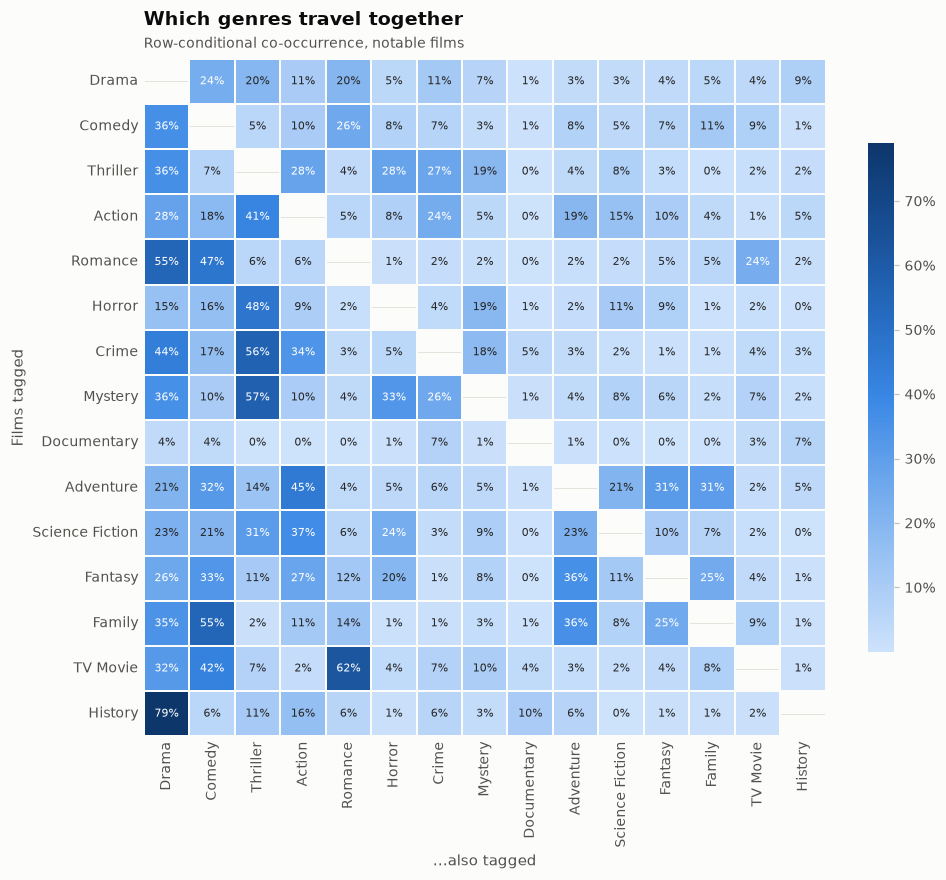

In [356]:
G15 = list(top_genres[:15])
onehot = pd.crosstab(g_long["id"], g_long["genres"]).reindex(columns=G15, fill_value=0).clip(upper=1)
co = onehot.T @ onehot
cond = co.div(np.diag(co), axis=0).mask(np.eye(len(co), dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cond, cmap=SEQ, annot=True, fmt=".0%", annot_kws={"size": 7.5}, linewidths=1, linecolor=SURFACE,
            ax=ax, cbar_kws={"format": PCT, "shrink": 0.75})
ax.set_xlabel("…also tagged"); ax.set_ylabel("Films tagged"); ax.tick_params(length=0)
titles(ax, "Which genres travel together", "Row-conditional co-occurrence, notable films")
save(fig, "11_genre_cooccurrence"); plt.show()

## Step 12: Recurring keywords and themes

Notable films with ≥1 keyword: 72.1% | distinct keywords: 12,883


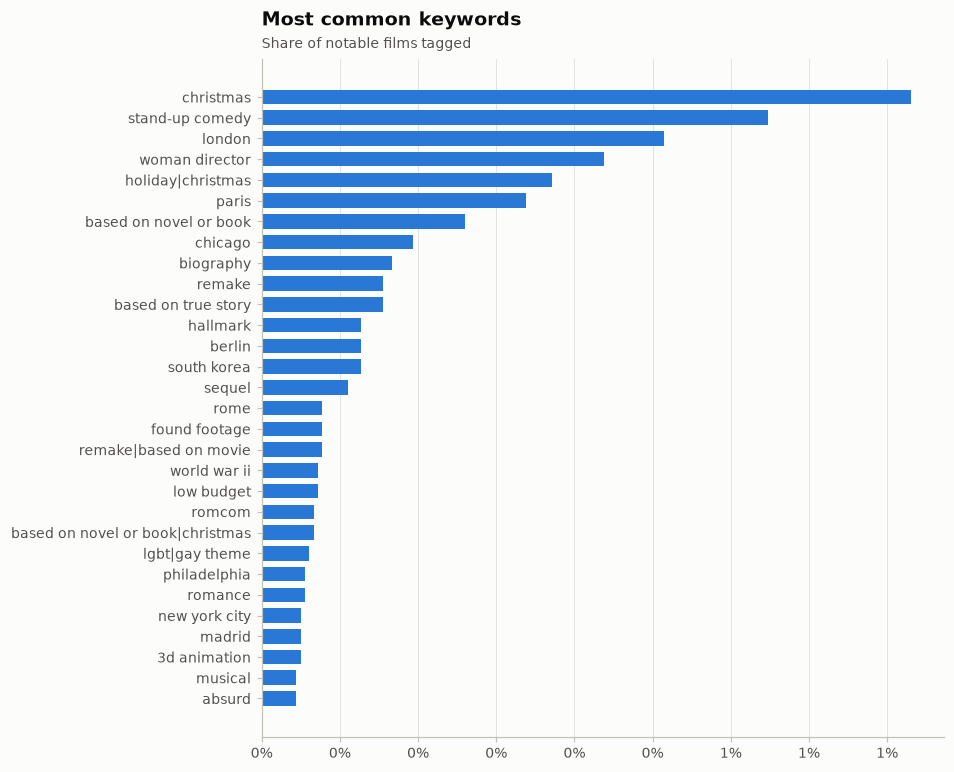

In [357]:
kw = explode_list(nb, "keywords", keep=("id", "year"))
kw["keywords"] = kw["keywords"].str.lower()
kw = kw.drop_duplicates(["id", "keywords"])
print(f"Notable films with ≥1 keyword: {nb['keywords'].notna().mean():.1%} | distinct keywords: {kw['keywords'].nunique():,}")

fig, ax = plt.subplots(figsize=(8, 8))
hbar(ax, kw["keywords"].value_counts().head(30) / len(nb), "Most common keywords",
     "Share of notable films tagged", fmt=PCT)
save(fig, "12_top_keywords"); plt.show()

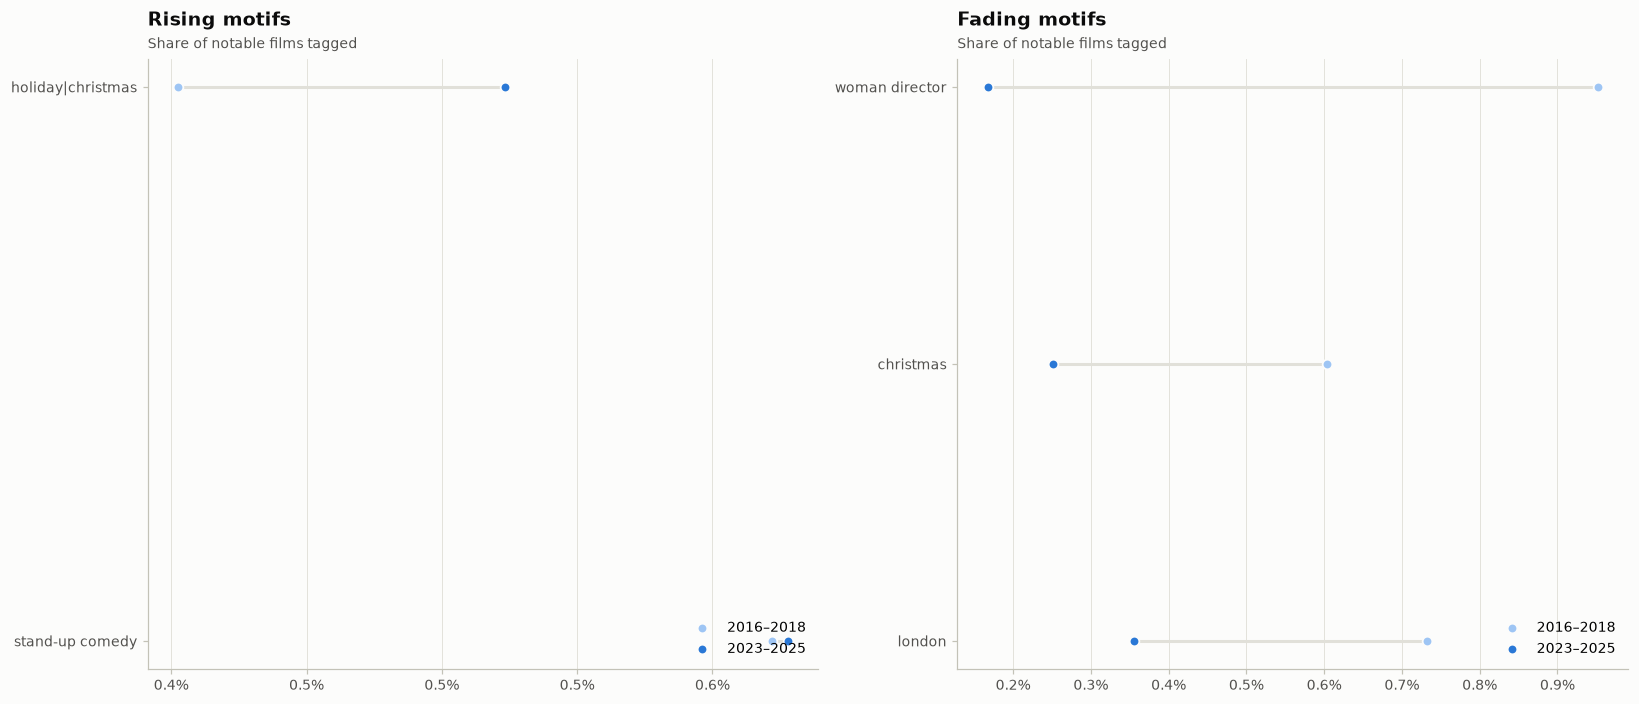

period,early,late,share_early,share_late,log2_change
keywords,,,,,
holiday|christmas,22,25,0.004,0.005,0.371
stand-up comedy,34,30,0.006,0.006,0.019
london,40,17,0.007,0.004,-0.994
christmas,33,12,0.006,0.003,-1.193
woman director,52,8,0.010,0.002,-2.364


In [358]:
EARLY = range(START_YEAR, START_YEAR + 3)
LATE  = range(LAST_FULL_YEAR - 2, LAST_FULL_YEAR + 1)
if min(LATE) <= max(EARLY):
    print("Warning: early and late windows overlap. Need more years of data.")
n_early, n_late = nb["year"].isin(EARLY).sum(), nb["year"].isin(LATE).sum()

kw["period"] = np.select([kw["year"].isin(EARLY), kw["year"].isin(LATE)], ["early", "late"], default="mid")
pt = (kw[kw["period"] != "mid"].groupby(["keywords", "period"]).size()
      .unstack(fill_value=0).reindex(columns=["early", "late"], fill_value=0))
pt = pt[(pt["early"] + pt["late"]) >= MIN_KW_FILMS].copy()
pt["share_early"] = pt["early"] / n_early
pt["share_late"]  = pt["late"] / n_late
pt["log2_change"] = np.log2((pt["late"] + 1) / n_late) - np.log2((pt["early"] + 1) / n_early)

def dumbbell(ax, frame, title, sub, ascending=True):
    frame = frame.sort_values("log2_change", ascending=ascending)
    y = np.arange(len(frame))
    ax.hlines(y, frame["share_early"], frame["share_late"], color=GRID, lw=2, zorder=1)
    ax.scatter(frame["share_early"], y, s=40, color=BLUE_LIGHT, zorder=3, edgecolor=SURFACE, lw=1.2,
               label=f"{min(EARLY)}–{max(EARLY)}")
    ax.scatter(frame["share_late"], y, s=40, color=BLUE, zorder=3, edgecolor=SURFACE, lw=1.2,
               label=f"{min(LATE)}–{max(LATE)}")
    ax.set_yticks(y, frame.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
    ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
    titles(ax, title, sub)

if len(pt):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    dumbbell(axes[0], pt[pt["log2_change"] > 0].nlargest(15, "log2_change"), "Rising motifs", "Share of notable films tagged")
    dumbbell(axes[1], pt[pt["log2_change"] < 0].nsmallest(15, "log2_change"), "Fading motifs", "Share of notable films tagged",
             ascending=False)
    plt.tight_layout(); save(fig, "12_keyword_risers_fallers"); plt.show()
pt.sort_values("log2_change", ascending=False).head(25)

**Probe specific motifs.** Edit `KEYWORD_PROBES` to follow themes you care about. TMDB's exact keyword spellings are in the top-keyword chart above, or search with `kw[kw.keywords.str.contains('...')]`.

Not found (check spelling): ['pandemic', 'artificial intelligence']


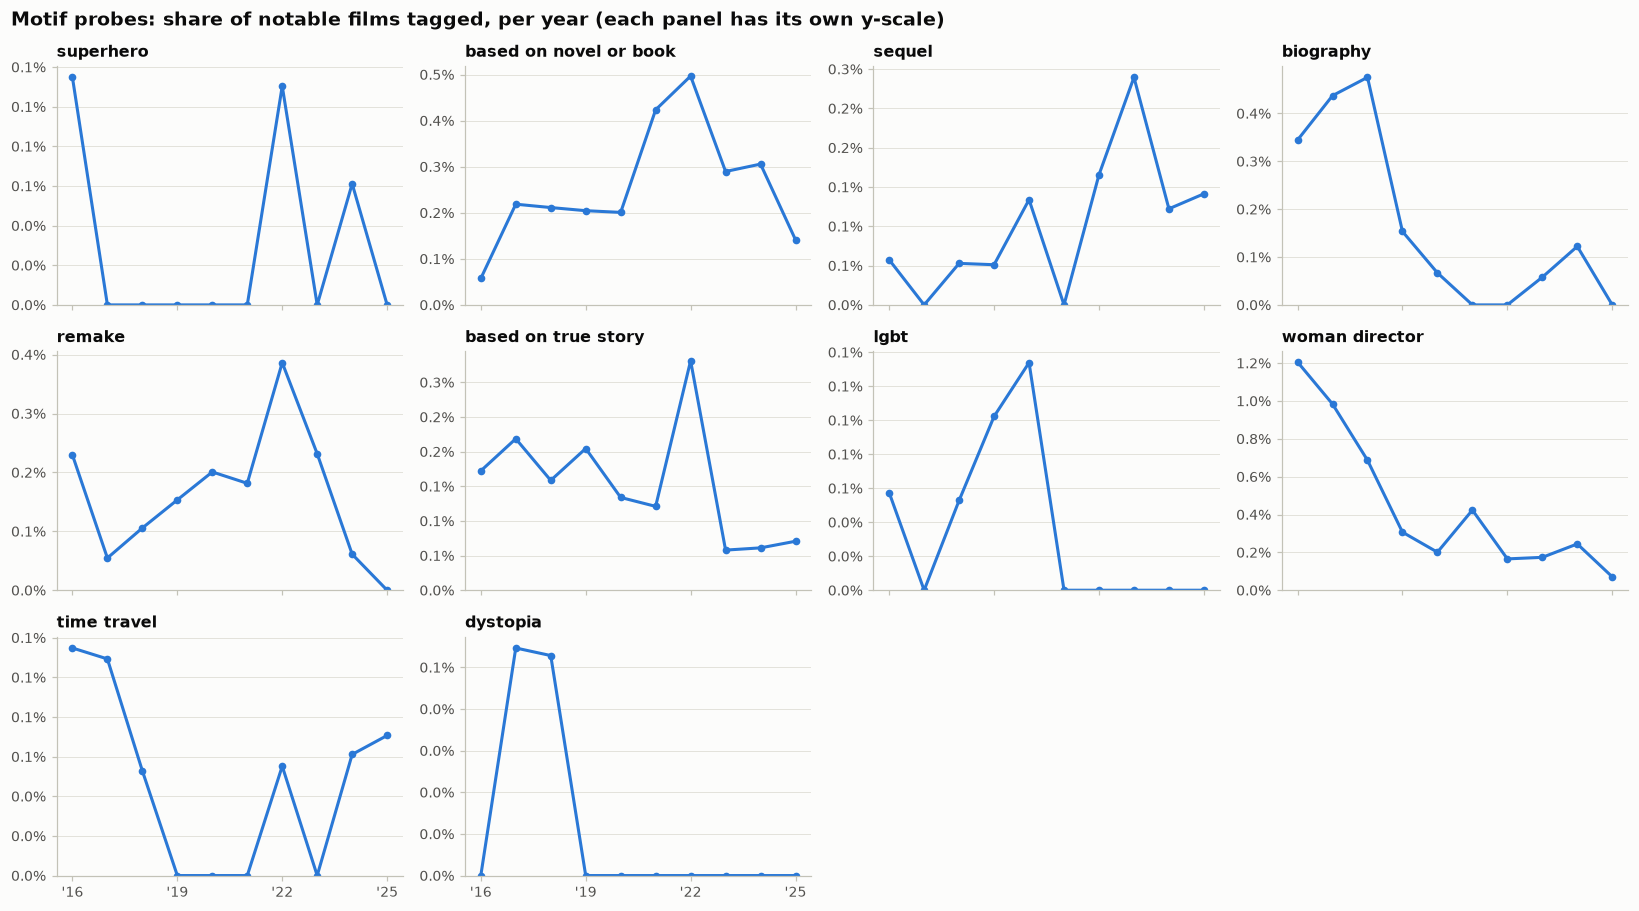

In [359]:
KEYWORD_PROBES = ["superhero", "pandemic", "artificial intelligence", "based on novel or book", "sequel",
                  "biography", "remake", "based on true story", "lgbt", "woman director", "time travel", "dystopia"]
by_year = kw.groupby(["keywords", "year"])["id"].nunique().unstack(fill_value=0).div(totals, axis=1)
found = [k for k in KEYWORD_PROBES if k in by_year.index]
print("Not found (check spelling):", [k for k in KEYWORD_PROBES if k not in by_year.index])
if found:
    ncol = 4; nrow = int(np.ceil(len(found) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 2.8 * nrow), sharex=True, squeeze=False)
    for ax, k in zip(axes.flat, found):
        s = by_year.loc[k, [y for y in by_year.columns if y <= LAST_FULL_YEAR]]
        ax.plot(s.index, s.values, color=BLUE, marker="o", markersize=4)
        ax.set_title(k, fontsize=10.5); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
        ax.set_ylim(bottom=0); ax.set_xticks(s.index[::3], [f"'{str(y)[2:]}" for y in s.index[::3]])
    for ax in axes.flat[len(found):]:
        ax.set_visible(False)
    fig.suptitle("Motif probes: share of notable films tagged, per year (each panel has its own y-scale)",
                 x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
    plt.tight_layout(); save(fig, "12_keyword_probes"); plt.show()

**Vocabulary by genre.** Keywords are curated tags. The `overview` text shows how each genre *describes itself*. TF-IDF picks out words that are distinctive to a genre rather than merely common.

In [360]:
from sklearn.feature_extraction.text import TfidfVectorizer

txt = nb[["primary_genre", "overview"]].dropna()
vec = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5, max_features=30_000, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X = vec.fit_transform(txt["overview"])
terms = np.array(vec.get_feature_names_out())
rows = {}
for g in txt["primary_genre"].value_counts().head(10).index:
    m = np.asarray(X[(txt["primary_genre"] == g).to_numpy()].mean(axis=0)).ravel()
    rows[g] = ", ".join(terms[m.argsort()[::-1][:10]])
pd.Series(rows, name="most distinctive overview words").to_frame()

,most distinctive overview words
Drama,"life, young, family, love, story, old, mother,..."
Comedy,"life, family, love, friends, new, comedy, old,..."
Action,"man, life, police, world, mission, save, famil..."
Horror,"young, house, family, group, home, mysterious,..."
Documentary,"documentary, world, life, story, film, footage..."
Thriller,"woman, life, young, man, family, police, murde..."
Romance,"love, life, christmas, romance, new, family, r..."
Crime,"police, murder, case, killer, crime, officer, ..."
Animation,"world, new, save, mysterious, young, friends, ..."
TV Movie,"christmas, new, family, holiday, town, help, l..."


## Step 13: Actors/actresses appearing the most

People analysis uses 7,886 of 18,055 notable films (US productions)


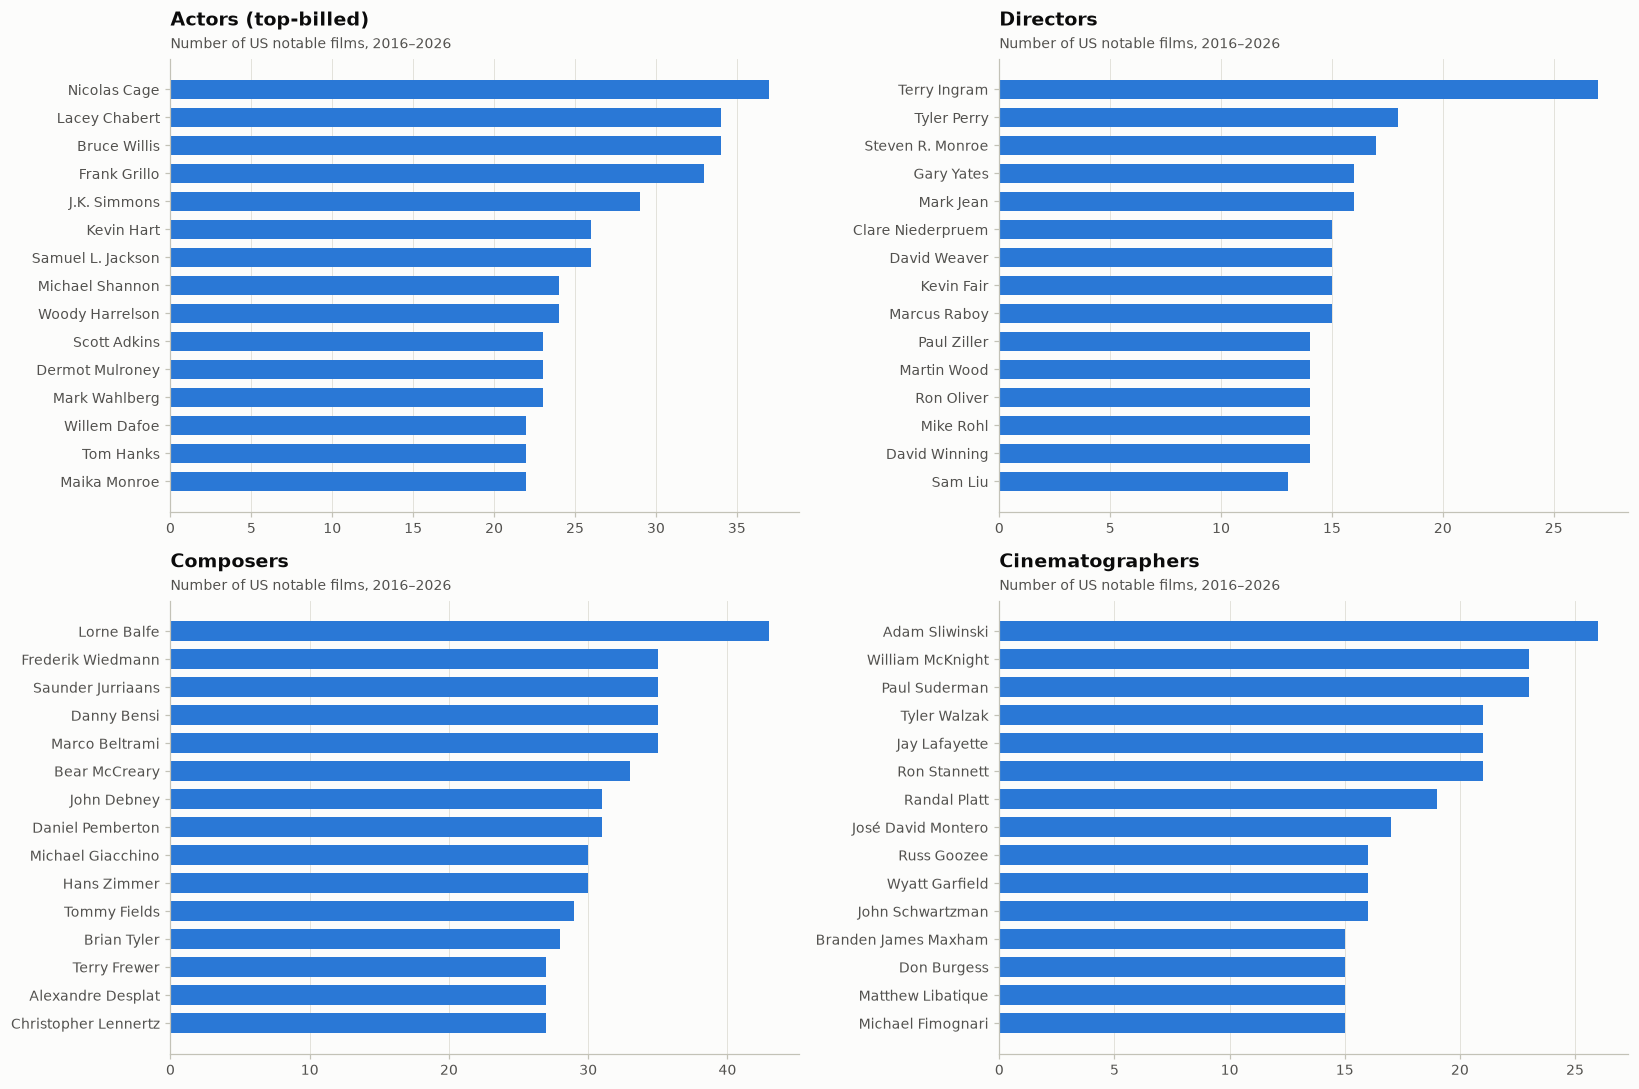

In [361]:
ROLES = {"cast": "Actors (top-billed)", "director": "Directors",
         "music_composer": "Composers", "director_of_photography": "Cinematographers"}
ROLES = {k: v for k, v in ROLES.items() if k in nb.columns}

# Restrict to US productions
US_ONLY = True
US_MODE = "any"
pcs = nb["production_countries"].fillna("")
is_us = pcs.str.fullmatch(r"United States( of America)?") if US_MODE == "only" else pcs.str.contains("United States", regex=False)
people_base = nb[is_us] if US_ONLY else nb
scope = "US notable films" if US_ONLY else "notable films"
print(f"People analysis uses {len(people_base):,} of {len(nb):,} notable films ({'US productions' if US_ONLY else 'all countries'})")

people = {c: explode_list(people_base, c, top_k=CAST_TOP_K if c == "cast" else None,
                          keep=("id", "year", "title", "release_date", "imdb_rating", "imdb_votes"))
          for c in ROLES}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (c, lab) in zip(axes.flat, ROLES.items()):
    hbar(ax, people[c][c].value_counts().head(15), lab, f"Number of {scope}, {START_YEAR}–{CURRENT_YEAR}")
plt.tight_layout(); save(fig, "13_top_people"); plt.show()

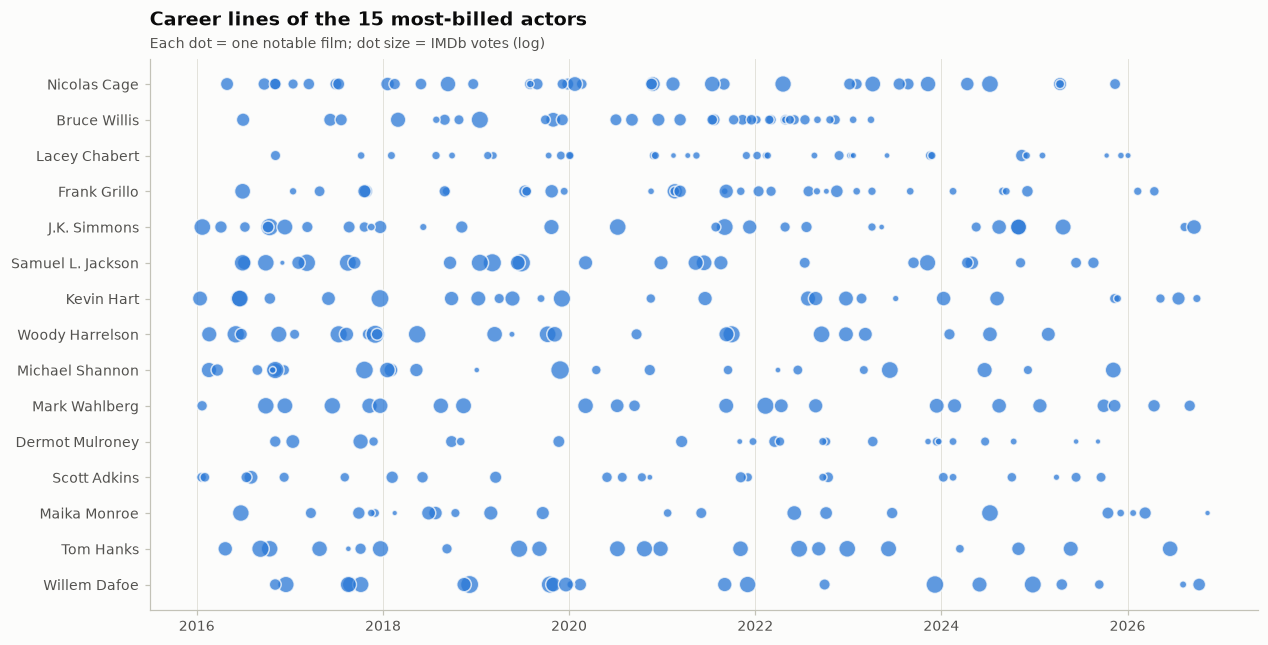

In [362]:
top_actors = people["cast"]["cast"].value_counts().head(15).index[::-1]
pc = people["cast"][people["cast"]["cast"].isin(top_actors)]
ypos = {a: i for i, a in enumerate(top_actors)}
fig, ax = plt.subplots(figsize=(13, 6.5))
lo = np.log10(NOTABLE_MIN_IMDB_VOTES)
sizes = 12 + 140 * (np.log10(pc["imdb_votes"]) - lo).clip(lower=0) / max(1e-9, np.log10(pc["imdb_votes"].max()) - lo)
ax.scatter(pc["release_date"], pc["cast"].map(ypos), s=sizes, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=1)
ax.set_yticks(range(len(top_actors)), top_actors); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
titles(ax, "Career lines of the 15 most-billed actors", "Each dot = one notable film; dot size = IMDb votes (log)")
save(fig, "13_career_lines"); plt.show()

In [363]:
d = people["director"].groupby("director").agg(films=("id", "nunique"), mean_imdb=("imdb_rating", "mean"),
                                                sd_imdb=("imdb_rating", "std"), total_votes=("imdb_votes", "sum"))
print("Directors with ≥ 4 notable films, highest mean IMDb rating:")
d[d["films"] >= 4].sort_values("mean_imdb", ascending=False).head(15)

Directors with ≥ 4 notable films, highest mean IMDb rating:


,films,mean_imdb,sd_imdb,total_votes
director,,,,
Denis Villeneuve,4,8.075,0.222,"3,574,402.000"
Brett Sullivan,4,7.950,0.443,"13,414.000"
Christopher Nolan,4,7.925,0.486,"3,235,943.000"
Jason Hehir,4,7.875,0.250,"12,962.000"
Paul Dugdale,6,7.867,0.763,"17,961.000"
Stan Lathan,8,7.800,0.438,"122,357.000"
Don Argott,5,7.760,0.733,"11,710.000"
Bo Burnham,7,7.729,0.682,"180,201.000"
Christopher Storer,4,7.725,0.629,"31,072.000"


In [364]:
assert "people_base" in globals(), "Run the characters cell first: it defines people_base (US productions)."

dir_films = explode_list(people_base, "director", keep=("id", "title", "year", "runtime", "imdb_rating", "vote_average",
                                                       "imdb_votes", "studio_tier"))
dstats = dir_films.groupby("director").agg(
    films=("id", "nunique"), mean_runtime=("runtime", "mean"), median_runtime=("runtime", "median"),
    sd_runtime=("runtime", "std"), mean_imdb=("imdb_rating", "mean"), sd_imdb=("imdb_rating", "std"),
    mean_tmdb=("vote_average", "mean"), total_votes=("imdb_votes", "sum"),
    big_box_share=("studio_tier", lambda s: s.isin(BIG_BOX_TIERS).mean()),
    first_year=("year", "min"), last_year=("year", "max"))
C, K = people_base["imdb_rating"].mean(), MIN_DIRECTOR_FILMS
dstats["adj_imdb"] = (dstats["films"] * dstats["mean_imdb"] + K * C) / (dstats["films"] + K)
dq = dstats[dstats["films"] >= MIN_DIRECTOR_FILMS].copy()
print(f"{len(dq):,} directors have ≥ {MIN_DIRECTOR_FILMS} {scope} (out of {len(dstats):,} directors). "
      f"Mean IMDb rating of those films = {C:.2f}")

def director_strip(ax, names, value_col, mean_col, title, sub, xlabel):
    names = list(names)[::-1]
    for i, d in enumerate(names):
        vals = dir_films.loc[dir_films["director"] == d, value_col].dropna()
        ax.scatter(vals, np.full(len(vals), i), s=24, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=0.8, zorder=2)
        ax.scatter(dq.loc[d, mean_col], i, marker="|", s=280, color=INK, linewidth=2, zorder=3)
    ax.set_yticks(range(len(names)), [f"{d} ({int(dq.loc[d, 'films'])})" for d in names])
    ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xlabel(xlabel)
    ax.scatter([], [], s=24, color=BLUE_LIGHT, label="one film")
    ax.scatter([], [], marker="|", s=120, color=INK, linewidth=2, label="director mean")
    ax.legend(loc="lower right")
    titles(ax, title, sub)

745 directors have ≥ 3 US notable films (out of 5,425 directors). Mean IMDb rating of those films = 5.92


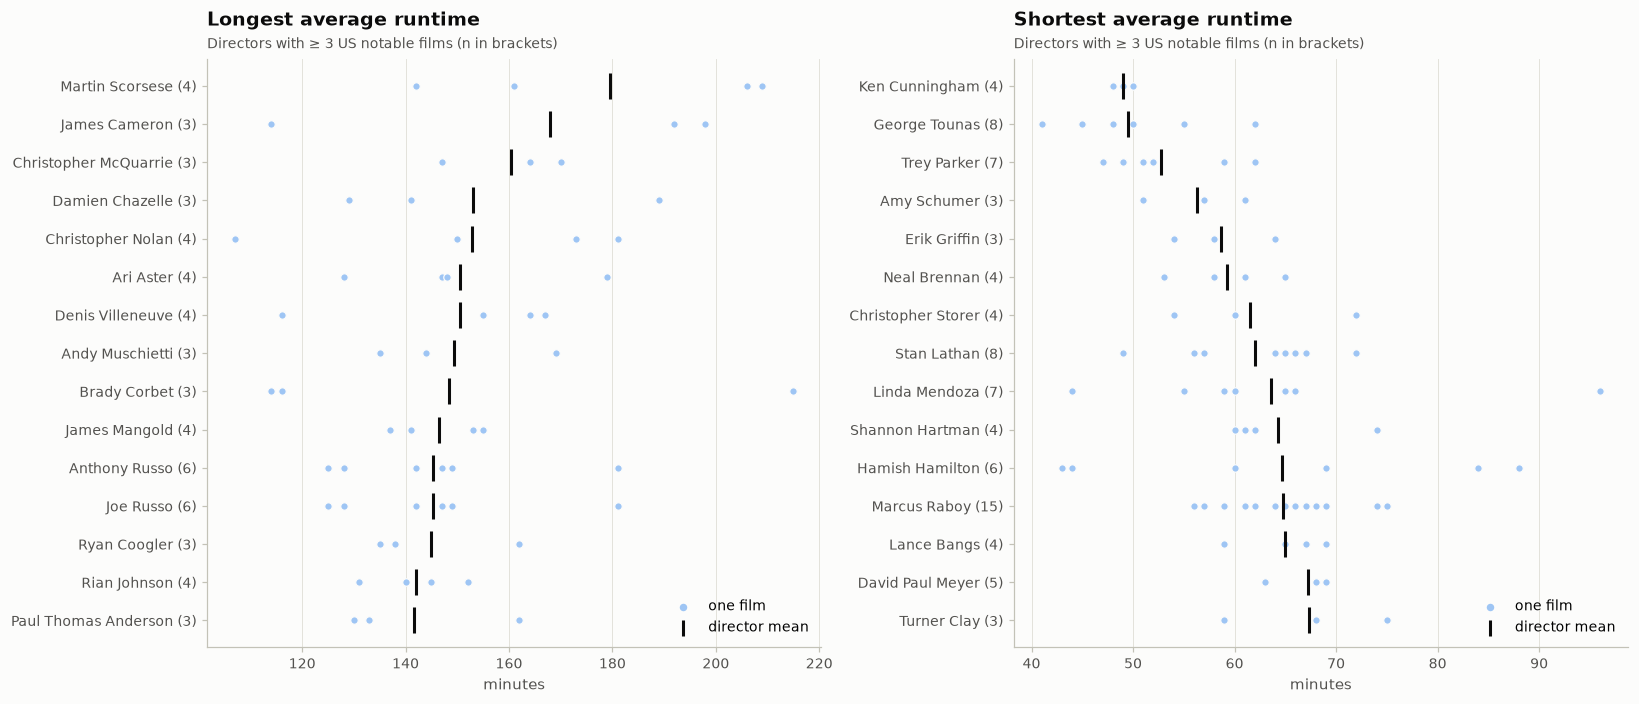

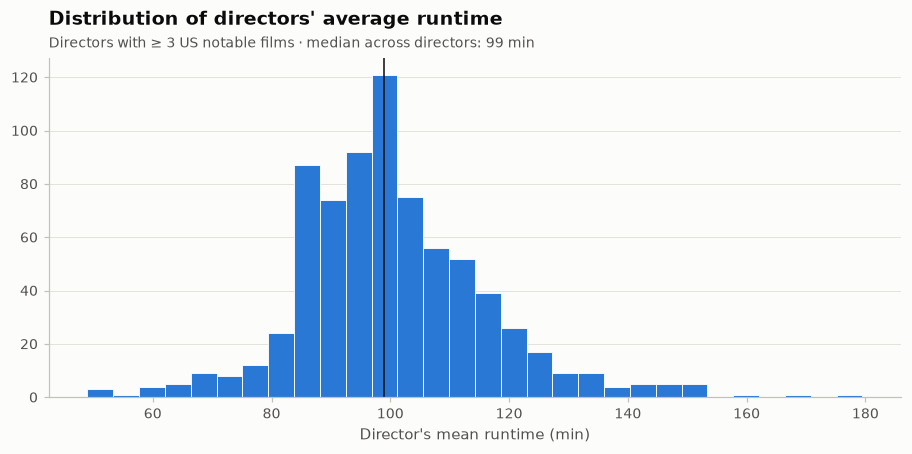

In [365]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
director_strip(axes[0], dq.nlargest(15, "mean_runtime").index, "runtime", "mean_runtime",
               "Longest average runtime", f"Directors with ≥ {MIN_DIRECTOR_FILMS} {scope} (n in brackets)", "minutes")
director_strip(axes[1], dq.nsmallest(15, "mean_runtime").index, "runtime", "mean_runtime",
               "Shortest average runtime", f"Directors with ≥ {MIN_DIRECTOR_FILMS} {scope} (n in brackets)", "minutes")
plt.tight_layout(); save(fig, "16_director_runtime"); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dq["mean_runtime"].dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(dq["mean_runtime"].median(), color=INK, lw=1)
ax.set_xlabel("Director's mean runtime (min)")
titles(ax, "Distribution of directors' average runtime",
       f"Directors with ≥ {MIN_DIRECTOR_FILMS} {scope} · median across directors: {dq['mean_runtime'].median():.0f} min")
save(fig, "16_director_runtime_hist"); plt.show()

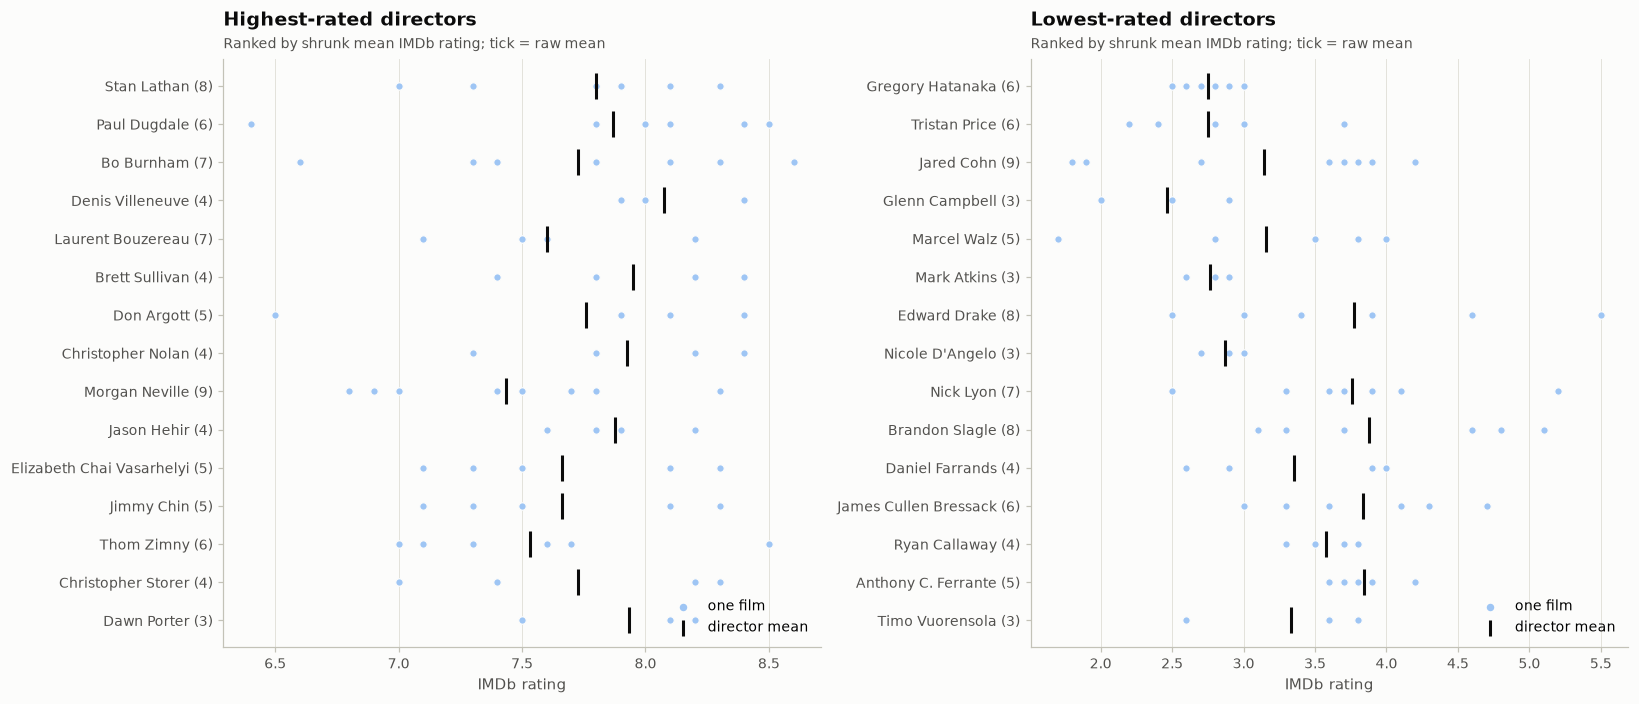

In [366]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
director_strip(axes[0], dq.nlargest(15, "adj_imdb").index, "imdb_rating", "mean_imdb",
               "Highest-rated directors", "Ranked by shrunk mean IMDb rating; tick = raw mean", "IMDb rating")
director_strip(axes[1], dq.nsmallest(15, "adj_imdb").index, "imdb_rating", "mean_imdb",
               "Lowest-rated directors", "Ranked by shrunk mean IMDb rating; tick = raw mean", "IMDb rating")
plt.tight_layout(); save(fig, "16_director_rating"); plt.show()

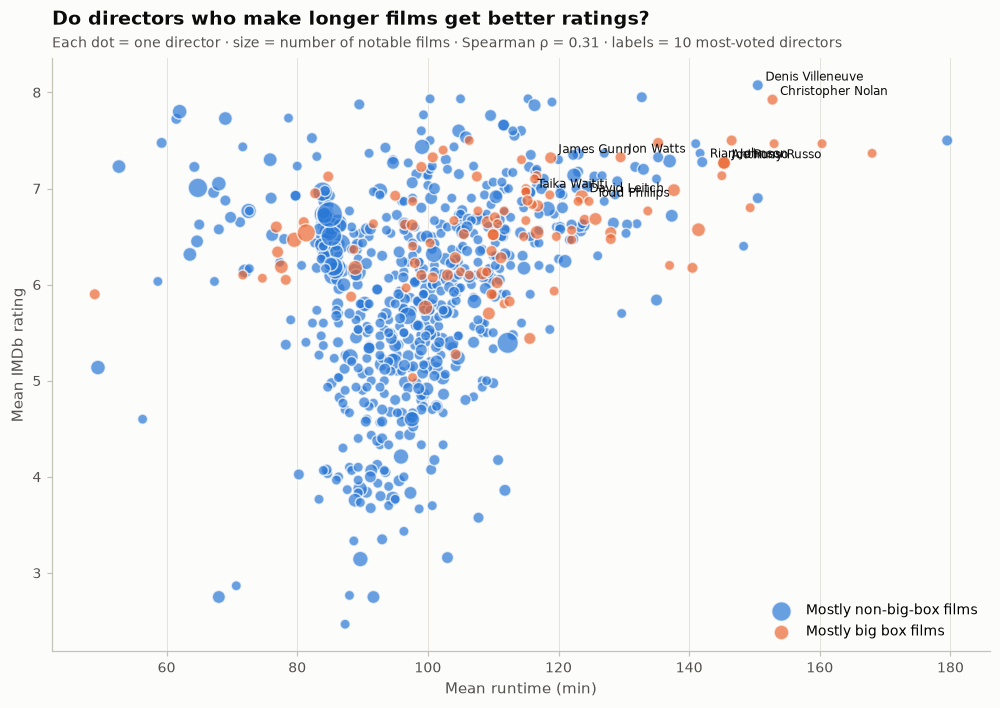

In [367]:
fig, ax = plt.subplots(figsize=(11, 7))
mostly_bb = dq["big_box_share"] >= 0.5
for mask, col, lab in [(~mostly_bb, BLUE, "Mostly non-big-box films"), (mostly_bb, ORANGE, "Mostly big box films")]:
    ax.scatter(dq.loc[mask, "mean_runtime"], dq.loc[mask, "mean_imdb"], s=14 + 10 * dq.loc[mask, "films"],
               color=col, alpha=0.7, edgecolor=SURFACE, linewidth=1, label=lab)
for d in dq.nlargest(10, "total_votes").index:
    ax.annotate(d, (dq.loc[d, "mean_runtime"], dq.loc[d, "mean_imdb"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=INK)
rho = dq[["mean_runtime", "mean_imdb"]].corr("spearman").iloc[0, 1]
ax.set_xlabel("Mean runtime (min)"); ax.set_ylabel("Mean IMDb rating"); ax.grid(axis="both")
ax.legend(loc="lower right")
titles(ax, "Do directors who make longer films get better ratings?",
       f"Each dot = one director · size = number of notable films · Spearman ρ = {rho:.2f} · labels = 10 most-voted directors")
save(fig, "16_director_runtime_vs_rating"); plt.show()

In [368]:
show_cols = ["films", "mean_runtime", "sd_runtime", "mean_imdb", "adj_imdb", "sd_imdb", "mean_tmdb",
             "total_votes", "big_box_share", "first_year", "last_year"]
print(f"Directors with ≥ {MIN_DIRECTOR_FILMS} notable films, sorted by shrunk IMDb rating "
      "(sort by any column with dq.sort_values('<column>'))")
dq.sort_values("adj_imdb", ascending=False)[show_cols].head(30).style.format({
    "mean_runtime": "{:.0f}", "sd_runtime": "{:.0f}", "mean_imdb": "{:.2f}", "adj_imdb": "{:.2f}", "sd_imdb": "{:.2f}",
    "mean_tmdb": "{:.2f}", "total_votes": "{:,.0f}", "big_box_share": "{:.0%}"}, na_rep="–")

Directors with ≥ 3 notable films, sorted by shrunk IMDb rating (sort by any column with dq.sort_values('<column>'))


,films,mean_runtime,sd_runtime,mean_imdb,adj_imdb,sd_imdb,mean_tmdb,total_votes,big_box_share,first_year,last_year
director,,,,,,,,,,,
Stan Lathan,8,62,7,7.80,7.29,0.44,7.22,"122,357",0%,2017,2023
Paul Dugdale,6,116,31,7.87,7.22,0.76,8.23,"17,961",17%,2018,2026
Bo Burnham,7,69,15,7.73,7.19,0.68,7.35,"180,201",0%,2016,2022
Denis Villeneuve,4,150,24,8.07,7.15,0.22,7.79,"3,574,402",25%,2016,2024
Laurent Bouzereau,7,105,42,7.60,7.10,0.45,7.31,"24,861",29%,2017,2025
Brett Sullivan,4,133,14,7.95,7.08,0.44,8.03,"13,414",0%,2017,2026
Don Argott,5,110,13,7.76,7.07,0.73,6.90,"11,710",0%,2017,2023
Christopher Nolan,4,153,33,7.92,7.07,0.49,7.67,"3,235,943",100%,2017,2026
Morgan Neville,9,99,11,7.43,7.05,0.48,7.23,"64,714",0%,2018,2026


## Step 14: Who works with who?

In [369]:
def pair_counts(a_col, b_col, top=15):
    a = people[a_col][["id", a_col]]
    b = people[b_col][["id", b_col]]
    m = a.merge(b, on="id")
    m = m[m[a_col] != m[b_col]]
    return (m.groupby([a_col, b_col])["id"].nunique().rename("films")
             .sort_values(ascending=False).head(top).reset_index())

if "music_composer" in people:
    print("Recurring director–composer partnerships"); display(pair_counts("director", "music_composer"))
print("Recurring director–actor partnerships"); display(pair_counts("director", "cast"))

Recurring director–composer partnerships


,director,music_composer,films
0,Alex Ranarivelo,Jamie Christopherson,8
1,George Tounas,Frederic Mauerhofer,8
2,Paul Feig,Theodore Shapiro,7
3,Guy Ritchie,Chris Benstead,7
4,Sam Liu,Frederik Wiedmann,6
5,Mike Flanagan,Taylor Stewart,6
6,David Lowery,Daniel Hart,6
7,Clare Niederpruem,Tommy Fields,6
8,Jeff Wamester,Kevin Riepl,6
9,Brian Brough,James Schafer,6


Recurring director–actor partnerships


,director,cast,films
0,Trey Parker,April Stewart,7
1,Terry Ingram,Lacey Chabert,7
2,Stan Lathan,Dave Chappelle,7
3,Trey Parker,Matt Stone,7
4,Trey Parker,Kimberly Brooks,7
5,Terry Ingram,Alison Sweeney,6
6,Martin Wood,Candace Cameron Bure,6
7,Edward Drake,Bruce Willis,6
8,George Tounas,Jannis Sky,6
9,Jeff Wamester,Jensen Ackles,5


In [370]:
edge_counter = Counter()
for xs in nb["cast"].dropna().str.split(LIST_SEP):
    names = sorted({x.strip() for x in xs[:CAST_TOP_K] if x.strip()})
    edge_counter.update(combinations(names, 2))
edges = pd.DataFrame([(a, b, w) for (a, b), w in edge_counter.items()], columns=["source", "target", "weight"])
print(f"Co-billing pairs: {len(edges):,} | pairs sharing ≥ {MIN_EDGE_WEIGHT} films: {(edges.weight >= MIN_EDGE_WEIGHT).sum():,}")

G = nx.Graph()
G.add_weighted_edges_from(edges[edges["weight"] >= MIN_EDGE_WEIGHT].itertuples(index=False, name=None))
if G.number_of_nodes() == 0:
    raise SystemExit("No repeated collaborations. Lower MIN_EDGE_WEIGHT.")
comps = sorted(nx.connected_components(G), key=len, reverse=True)
H = G.subgraph(comps[0]).copy()
print(f"Graph: {G.number_of_nodes():,} actors, {G.number_of_edges():,} links, {len(comps):,} components; "
      f"largest component = {H.number_of_nodes():,} actors")

btw = nx.betweenness_centrality(H, k=min(400, H.number_of_nodes()), seed=81)
communities = sorted(nx.community.louvain_communities(H, weight="weight", seed=81), key=len, reverse=True)
comm_of = {n: i for i, c in enumerate(communities) for n in c}
film_counts = people["cast"]["cast"].value_counts()

net = pd.DataFrame({
    "notable_films": pd.Series({n: film_counts.get(n, 0) for n in H}),
    "collaborators": pd.Series(dict(H.degree())),
    "weighted_degree": pd.Series(dict(H.degree(weight="weight"))),
    "betweenness": pd.Series(btw),
    "community": pd.Series(comm_of),
})
print(f"Louvain communities in largest component: {len(communities)} (sizes of top 5: {[len(c) for c in communities[:5]]})")
net.sort_values("betweenness", ascending=False).head(15)

Co-billing pairs: 166,620 | pairs sharing ≥ 2 films: 4,021
Graph: 3,340 actors, 4,021 links, 668 components; largest component = 524 actors
Louvain communities in largest component: 17 (sizes of top 5: [71, 68, 64, 44, 39])


,notable_films,collaborators,weighted_degree,betweenness,community
Akshay Kumar,1,20,44,0.192,0
Prakash Raj,0,25,56,0.190,2
Vennela Kishore,0,23,55,0.149,6
Prithviraj Sukumaran,0,9,19,0.146,9
Rakul Preet Singh,0,10,25,0.131,0
Naresh,0,15,34,0.126,4
Nithiin,0,4,8,0.125,5
Tovino Thomas,0,19,42,0.123,1
Jisshu Sengupta,0,2,4,0.113,5
Idhika Paul,0,3,6,0.111,5


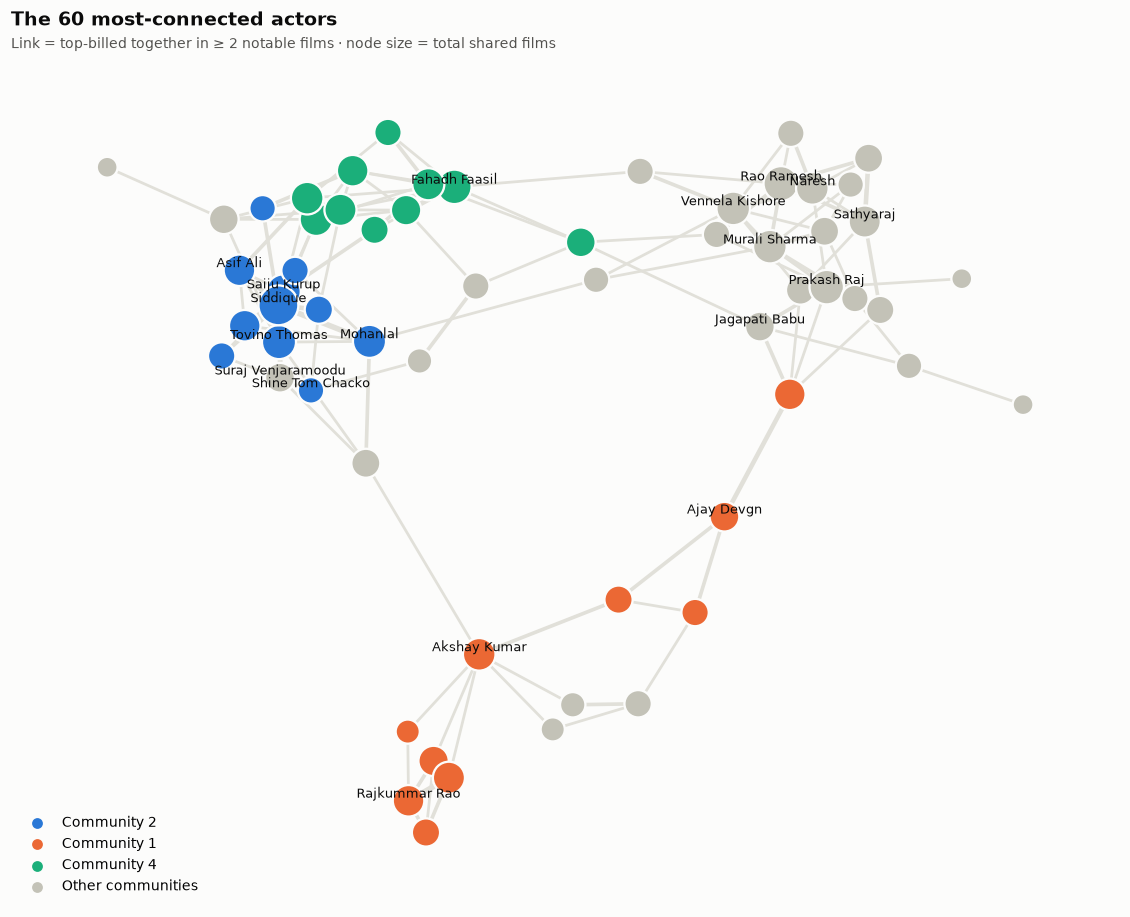

Community 2 (68 actors): Siddique, Saiju Kurup, Tovino Thomas, Mohanlal, Asif Ali, Shine Tom Chacko, Nivin Pauly, Indrans
Community 1 (71 actors): Akshay Kumar, Ajay Devgn, Rajkummar Rao, Rakul Preet Singh, Riteish Deshmukh, Sanjay Mishra, Kriti Sanon, Pankaj Tripathi
Community 4 (44 actors): Fahadh Faasil, Jaffer Idukki, Chemban Vinod Jose, Sharafudheen, Joju George, Arjun Ashokan, Dileesh Pothan, Soubin Shahir


In [371]:
TOP_N = 60
S = H.subgraph(net["weighted_degree"].nlargest(TOP_N).index).copy()
pos = nx.spring_layout(S, seed=7, weight="weight", k=1.2 / np.sqrt(max(1, S.number_of_nodes())))
present = pd.Series([comm_of[n] for n in S]).value_counts().index[:3]
cmap_c = {c: SERIES[i] for i, c in enumerate(present)}
node_colors = [cmap_c.get(comm_of[n], AXIS) for n in S]
wdeg = np.array([S.degree(n, weight="weight") for n in S])

fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_edges(S, pos, ax=ax, edge_color=GRID, width=[0.6 + 0.6 * S[u][v]["weight"] for u, v in S.edges()])
node_size = 30 + 650 * np.sqrt(wdeg / wdeg.max())
nx.draw_networkx_nodes(S, pos, ax=ax, node_color=node_colors, node_size=node_size, edgecolors=SURFACE, linewidths=1.5)
label_nodes = net.loc[list(S)].nlargest(18, "weighted_degree").index
nx.draw_networkx_labels(S, pos, labels={n: n for n in label_nodes}, ax=ax, font_size=8.5, font_color=INK,
                        verticalalignment="bottom")
for i, c in enumerate(present):
    ax.scatter([], [], color=SERIES[i], s=50, label=f"Community {c + 1}")
ax.scatter([], [], color=AXIS, s=50, label="Other communities")
ax.legend(loc="lower left"); ax.axis("off")
titles(ax, f"The {TOP_N} most-connected actors", f"Link = top-billed together in ≥ {MIN_EDGE_WEIGHT} notable films · node size = total shared films")
save(fig, "14_actor_network"); plt.show()

for i, c in enumerate(present):
    members = net[net["community"] == c].nlargest(8, "weighted_degree").index.tolist()
    print(f"Community {c + 1} ({len(communities[c])} actors): {', '.join(members)}")

## Step 15: Key numbers (for slides and report)

In [372]:
facts = {
    "Rows in input file (pre-filtered 2016+)": f"{load_stats['rows_in_file']:,}",
    "Released 2016+ after cleaning": f"{len(df):,}",
    "Feature films (≥ 40 min)": f"{df['is_feature'].sum():,}",
    f"Notable (≥ {NOTABLE_MIN_IMDB_VOTES:,} IMDb votes)": f"{len(nb):,} ({len(nb)/len(df):.1%} of 2016+)",
    "Budget known (notable)": f"{nb['budget'].notna().mean():.1%}",
    "Revenue known (notable)": f"{nb['revenue'].notna().mean():.1%}",
    "Keywords present (notable)": f"{nb['keywords'].notna().mean():.1%}",
    "Median IMDb rating (notable)": f"{nb['imdb_rating'].median():.1f}",
    "Median runtime (notable)": f"{nb['runtime'].median():.0f} min",
    "English-language share (notable)": f"{(nb['original_language']=='en').mean():.1%}",
    "Most common genre (notable)": f"{top_genres[0]} ({gy.loc[top_genres[0]].mean():.0%} of films/yr)",
    "Actors in collaboration graph": f"{G.number_of_nodes():,}",
    "Latest release date in data": str(df['release_date'].max().date()),
}
pd.Series(facts, name="value").to_frame()

,value
Rows in input file (pre-filtered 2016+),"485,176"
Released 2016+ after cleaning,"485,031"
Feature films (≥ 40 min),"178,303"
"Notable (≥ 1,000 IMDb votes)","18,055 (3.7% of 2016+)"
Budget known (notable),21.1%
Revenue known (notable),27.1%
Keywords present (notable),72.1%
Median IMDb rating (notable),6.3
Median runtime (notable),102 min
English-language share (notable),54.0%


### Export processed data

In [373]:
export_cols = ["id", "imdb_id", "title", "release_date", "year", "month", "runtime", "genres", "primary_genre",
               "original_language", "vote_average", "vote_count", "imdb_rating", "imdb_votes", "popularity",
               "budget", "revenue", "roi", "director", "cast", "keywords", "certification_us"]
nb[[c for c in export_cols if c in nb.columns]].to_csv(OUT_DIR / "notable_films.csv", index=False)
gy.reset_index().melt(id_vars="genres", var_name="year", value_name="share").to_csv(OUT_DIR / "genre_year_share.csv", index=False)
pt.reset_index().to_csv(OUT_DIR / "keyword_trends.csv", index=False)
edges[edges["weight"] >= MIN_EDGE_WEIGHT].to_csv(OUT_DIR / "actor_edges.csv", index=False)
net.reset_index(names="actor").to_csv(OUT_DIR / "actor_nodes.csv", index=False)
pd.DataFrame(clean_log).to_csv(OUT_DIR / "cleaning_log.csv", index=False)
print(sorted(p.name for p in OUT_DIR.iterdir()))

['actor_edges.csv', 'actor_nodes.csv', 'cleaning_log.csv', 'genre_year_share.csv', 'keyword_trends.csv', 'notable_films.csv']


<H1> Outlier detection and filtering

In [374]:
# Titles runing longer than 3.5 hours
LONG_MIN, VERY_LONG_MIN = 210, 360  # 3.5 hours, 6 hours
long_all = df[df["runtime"] > LONG_MIN]

print("How many titles are this long")
display(pd.DataFrame({
    "all 2016+ titles": [(df["runtime"] > LONG_MIN).sum(), (df["runtime"] > VERY_LONG_MIN).sum()],
    "notable films":    [(nb["runtime"] > LONG_MIN).sum(), (nb["runtime"] > VERY_LONG_MIN).sum()],
}, index=["> 3.5 hours", "> 6 hours"]))

print("Main genre of titles over 3.5 hours")
display(pd.DataFrame({"all": long_all["primary_genre"].value_counts(),
                      "notable": long_all.loc[long_all["notable"], "primary_genre"].value_counts()})
          .fillna(0).astype(int).sort_values("all", ascending=False).head(12))

cols = ["title", "year", "runtime", "genres", "imdb_votes", "imdb_rating", "notable"]
fmt = {"runtime": "{:.0f}", "imdb_votes": "{:,.0f}", "imdb_rating": "{:.1f}"}
print("Most-voted titles over 3.5 hours")
display(long_all.sort_values("imdb_votes", ascending=False)[cols].head(20).style.format(fmt, na_rep="–").hide(axis="index"))
print("Longest notable films")
display(nb.nlargest(15, "runtime")[cols].style.format(fmt, na_rep="–").hide(axis="index"))

How many titles are this long


,all 2016+ titles,notable films
> 3.5 hours,824,10
> 6 hours,0,0


Main genre of titles over 3.5 hours


,all,notable
primary_genre,,
Action,171,3
Music,153,0
Documentary,86,2
Drama,34,4
Comedy,25,1
Horror,9,0
Animation,6,0
Fantasy,3,0
Thriller,3,0


Most-voted titles over 3.5 hours


title,year,runtime,genres,imdb_votes,imdb_rating,notable
The Brutalist,2024,215,Drama,"166,747",7.2,True
Dhurandhar,2025,214,"Action, Crime, Thriller","153,758",8.2,True
Dhurandhar: The Revenge,2026,235,"Action, Crime, Thriller","75,463",8.2,True
Pushpa 2 - The Rule,2024,225,"Drama, Action","69,302",6.0,True
Haunted Hotel,2025,220,Comedy,"12,038",7.8,True
An Elephant Sitting Still,2018,235,Drama,"9,584",7.8,True
Bāhubali: The Epic,2025,224,"Action, Drama","2,671",8.2,True
Musk,2026,238,Documentary,"2,605",7.1,True
The Woman Who Left,2016,229,Drama,"1,836",7.1,True
Mr. Bachmann and His Class,2021,217,Documentary,"1,085",8.0,True


Longest notable films


title,year,runtime,genres,imdb_votes,imdb_rating,notable
Musk,2026,238,Documentary,"2,605",7.1,True
An Elephant Sitting Still,2018,235,Drama,"9,584",7.8,True
Dhurandhar: The Revenge,2026,235,"Action, Crime, Thriller","75,463",8.2,True
The Woman Who Left,2016,229,Drama,"1,836",7.1,True
Pushpa 2 - The Rule,2024,225,"Drama, Action","69,302",6.0,True
Bāhubali: The Epic,2025,224,"Action, Drama","2,671",8.2,True
Haunted Hotel,2025,220,Comedy,"12,038",7.8,True
Mr. Bachmann and His Class,2021,217,Documentary,"1,085",8.0,True
The Brutalist,2024,215,Drama,"166,747",7.2,True
Dhurandhar,2025,214,"Action, Crime, Thriller","153,758",8.2,True
